# Modelado y validación · F1 · Grupo 14

Ciencia de Datos · UTN FRM · 2026 · Entrega 3

Este notebook parte de las decisiones del EDA (Entrega 2) y elige el modelo que va a usar la
aplicación de la Entrega 4. Sigue el orden de la consigna:

| Sección | Contenido |
|---|---|
| 1 | Planteo: qué se predice y con qué métrica |
| 2 | Cómo se parten los datos |
| 3 | El pipeline, el piso y la referencia de la grilla |
| 4 | Qué le pasa al número según cómo se parte |
| 5 | Comparación de modelos |
| 6 | Hiperparámetros y columnas probadas |
| 7 | El modelo final sobre el test 2026, con y sin abandonos |
| 8 | Dónde se equivoca |
| 9 | El campeonato 2026 con los puntos predichos |
| 10 | En qué se apoya y chequeo de fuga |
| 11 | Conclusión y limitaciones |
| 12 | Modelo para la aplicación |

### Lo que se toma del EDA sin volver a discutirlo

- **Las columnas:** la grilla, `Q_Best_seconds_DBT_%`, la distancia en puntos al líder, las mejores
  vueltas de prácticas con SOFT, MED y HARD (versión DBT) y las dos columnas de desgaste.
- **Lo que queda afuera:** la telemetría (H3), el contexto de la fecha (H4), las versiones ABS, las
  columnas redundantes y los identificadores `TeamId` y `DriverId` (cambian de fuerza con la era).
  Algunas de estas se vuelven a probar en la Sección 6, para medir con y sin cada una.
- **La limpieza:** rondas con filas duplicadas eliminadas completas y grilla en 0 pasada a nulo.

### Qué cambió desde la Entrega 2

- `RACE_Finished` se toma corregido: desde 2023 los pilotos doblados cuentan como terminados. No entra
  al modelo (se conoce después de la carrera); se usa solo para medir el error con y sin abandonos.
- El desgaste ya no se calcula afuera: lo calcula el pipeline a partir de las vueltas en segundos.

Se corre de arriba hacia abajo. La semilla se define en la primera celda de código y se pasa a todo
lo que la acepta.

## Sección 1: Planteo

### Herramientas, semilla y carga

Misma carga y misma función `mostrar` que en el EDA. Se agrega `transform_output="pandas"` para que
cada paso del pipeline conserve los nombres de las columnas, que hace falta para leer los
coeficientes al final. El ranking por carrera usa LightGBM.

In [ ]:
import os
import sys
import subprocess
import warnings
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

try:
    from lightgbm import LGBMRanker
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], check=True)
    from lightgbm import LGBMRanker

from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.model_selection import KFold, GroupKFold, ParameterGrid
from sklearn.metrics import roc_auc_score

SEMILLA = 14
np.random.seed(SEMILLA)
set_config(transform_output="pandas")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

ARCHIVO = "f1_all_full_v2.parquet"
ID_DRIVE = "1TrP80Sx4-ic2XYvYNTfZJZsxBXcboZF2"

if not os.path.exists(ARCHIVO):
    import gdown
    gdown.download(id=ID_DRIVE, output=ARCHIVO, quiet=True)

df_raw = pd.read_parquet(ARCHIVO)

# Solo para medir con y sin abandonos: RACE_Finished (corregido) del dataset del proyecto.
# No es columna del modelo: se conoce después de la carrera.
ARCHIVO_TERMINO = "f1_all_postEDA.parquet"
ID_DRIVE_TERMINO = "19JrHUOglFGko9RrnDOxiNtDzSKW2CK8g"

if not os.path.exists(ARCHIVO_TERMINO):
    try:
        import gdown
        gdown.download(id=ID_DRIVE_TERMINO, output=ARCHIVO_TERMINO, quiet=True)
    except Exception as error:
        print(f"No se pudo descargar {ARCHIVO_TERMINO}: {error}")
termino = pd.read_parquet(ARCHIVO_TERMINO) if os.path.exists(ARCHIVO_TERMINO) else None
if termino is not None and "RACE_Finished" not in termino.columns:
    print(f"{ARCHIVO_TERMINO} no tiene RACE_Finished.")
    termino = None
if termino is not None:
    termino = termino[["DriverId", "Year", "RoundNumber", "RACE_Finished"]]
else:
    print(f"Falta {ARCHIVO_TERMINO}: las métricas sin abandonos quedan vacías.")

target = "RACE_Position"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

AZUL, ROJO, GRIS, AMARILLO = "#2B5C8F", "#B5402C", "#8C8C8C", "#E3A72F"
COLORES_ZONA = {"verde": "#c8e6c9", "amarillo": "#fff3b0", "rojo": "#f8c4c4"}


def mostrar(tabla, titulo=None, decimales=2, zonas=None, texto_largo=False, gradiente=None):
    # Tabla formateada: título arriba, coma decimal y guion en los vacíos.
    sty = tabla.style.format(precision=decimales, decimal=",", na_rep="—")
    if titulo:
        sty = sty.set_caption(titulo)
    sty = sty.set_table_styles([
        {"selector": "caption",
         "props": "caption-side: top; text-align: left; font-weight: bold; font-size: 1.05em; padding-bottom: 6px;"},
        {"selector": "th", "props": "text-align: left;"},
    ])
    if zonas:
        sty = sty.map(lambda v: f"background-color: {COLORES_ZONA[v]}; color: #222"
                      if isinstance(v, str) and v in COLORES_ZONA else "", subset=zonas)
    if gradiente:
        sty = sty.background_gradient(cmap="RdYlGn", vmin=0, vmax=100, subset=gradiente)
    if texto_largo:
        sty = sty.set_properties(**{"white-space": "normal", "text-align": "left", "max-width": "460px"})
    display(sty)

### Limpieza (la misma del EDA)

Se repiten solo las correcciones que tocan a las columnas del modelo:

1. **Rondas con duplicados, afuera completas.** En 2023-R11 y 2025-R16 hay filas cargadas dos veces
   y no hay forma de separar las correctas sin escribir a mano cuáles son. Se sacan las dos rondas.
2. **Grilla en 0 pasada a nulo.** Son largadas desde boxes o sin lugar asignado, no una posición.
3. **Quién terminó, solo para medir.** `RACE_Finished` se une por piloto y fecha y se guarda como
   `Terminó`. No entra a ningún modelo.

Los ceros de telemetría y de posiciones de campeonato no se tocan porque esas columnas no entran.

In [ ]:
df = df_raw.copy()
limpieza = {"Filas del dataset original": len(df)}

claves_duplicadas = (df[df.duplicated(subset=["DriverId", "Year", "RoundNumber"])]
                     [["Year", "RoundNumber"]].drop_duplicates())
rondas_a_borrar = list(claves_duplicadas.itertuples(index=False, name=None))
filas_a_mantener = ~df.set_index(["Year", "RoundNumber"]).index.isin(rondas_a_borrar)
df = df[filas_a_mantener].reset_index(drop=True)
limpieza["Rondas eliminadas por duplicados"] = len(rondas_a_borrar)
limpieza["Filas eliminadas con esas rondas"] = limpieza["Filas del dataset original"] - len(df)

limpieza["Q_GridPosition: ceros pasados a nulo"] = int((df["Q_GridPosition"] == 0).sum())
df["Q_GridPosition"] = df["Q_GridPosition"].replace(0, np.nan)

if termino is not None:
    df = df.merge(termino, on=["DriverId", "Year", "RoundNumber"], how="left", validate="one_to_one")
    df["Terminó"] = df.pop("RACE_Finished").astype("boolean")
    limpieza["Filas sin dato de RACE_Finished"] = int(df["Terminó"].isna().sum())
    limpieza["Filas que no terminaron (abandonos)"] = int((df["Terminó"] == False).sum())
else:
    df["Terminó"] = pd.Series(pd.NA, index=df.index, dtype="boolean")
limpieza["Filas del dataset limpio"] = len(df)

mostrar(pd.Series(limpieza).to_frame("Cantidad"), "Limpieza aplicada")

,Cantidad
Filas del dataset original,3754
Rondas eliminadas por duplicados,2
Filas eliminadas con esas rondas,50
Q_GridPosition: ceros pasados a nulo,45
Filas sin dato de RACE_Finished,0
Filas que no terminaron (abandonos),543
Filas del dataset limpio,3704


### Qué se predice: un puntaje de 0 a 1 por piloto y, con él, el puesto

Es una **regresión**. El modelo no predice el número de puesto directamente: para cada piloto predice
un **puntaje entre 0 y 1**, la posición relativa dentro de su carrera, donde **0 es el ganador y 1 el
último**. Después se ordenan los pilotos de cada GP por ese puntaje y el orden da el **puesto
predicho**, que es lo que se compara con `RACE_Position`.

Hay dos motivos para hacerlo así:

- **No todos los GP tienen la misma cantidad de autos** (19, 20 o 22). Llevar el puesto a 0–1 hace
  que "último" signifique lo mismo en todas las carreras.
- **Al ordenar dentro de la carrera, cada puesto se asigna una sola vez.** Una regresión sobre el
  número de puesto puede darle 3,4 a dos pilotos de la misma carrera; el orden no.

,Valor
Carreras,184
Autos por carrera (mín / mediana / máx),19 / 20 / 22
Filas donde Puesto = RACE_Position (%),"100,00"
Puesto_01 (mín / máx),0 / 1


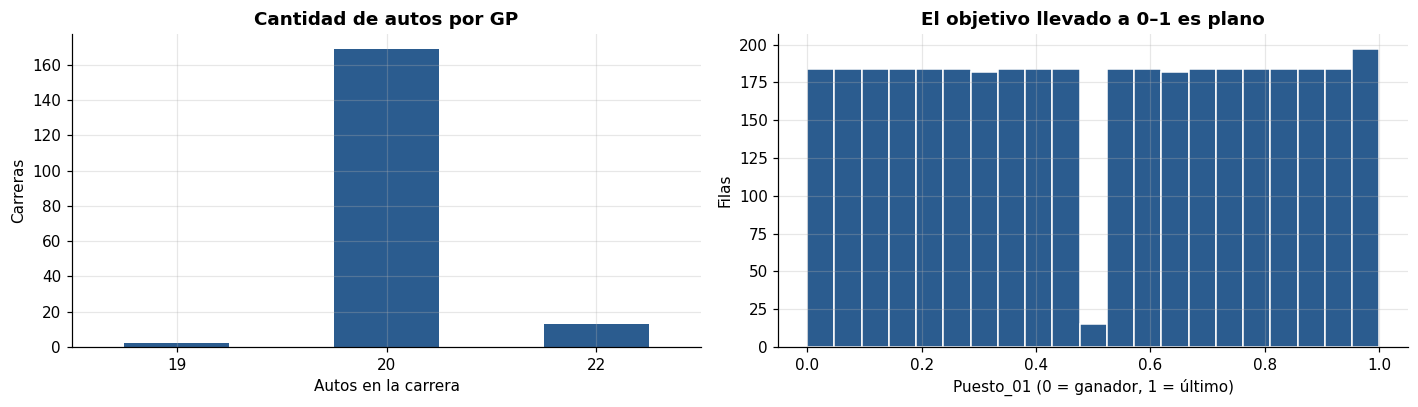

In [ ]:
df = df.sort_values(["Year", "RoundNumber", target]).reset_index(drop=True)
df["Carrera"] = df["Year"].astype(str) + "-R" + df["RoundNumber"].astype(int).astype(str).str.zfill(2)
df["Autos_en_carrera"] = df.groupby("Carrera")["DriverId"].transform("size")
df["Puesto"] = df.groupby("Carrera")[target].rank(method="first")
df["Puesto_01"] = (df["Puesto"] - 1) / (df["Autos_en_carrera"] - 1)

autos = df.groupby("Carrera")["Autos_en_carrera"].first()
mostrar(pd.Series({
    "Carreras": df["Carrera"].nunique(),
    "Autos por carrera (mín / mediana / máx)": f"{autos.min()} / {int(autos.median())} / {autos.max()}",
    "Filas donde Puesto = RACE_Position (%)": round((df["Puesto"] == df[target]).mean() * 100, 1),
    "Puesto_01 (mín / máx)": f"{df['Puesto_01'].min():.0f} / {df['Puesto_01'].max():.0f}",
}, dtype=object).to_frame("Valor"), "El objetivo del modelo")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
autos.value_counts().sort_index().plot.bar(ax=axes[0], color=AZUL, rot=0)
axes[0].set_xlabel("Autos en la carrera")
axes[0].set_ylabel("Carreras")
axes[0].set_title("Cantidad de autos por GP")
axes[1].hist(df["Puesto_01"], bins=21, color=AZUL, edgecolor="white")
axes[1].set_xlabel("Puesto_01 (0 = ganador, 1 = último)")
axes[1].set_ylabel("Filas")
axes[1].set_title("El objetivo llevado a 0–1 es plano")
plt.tight_layout()
plt.show()

### Las columnas del modelo

Son las 8 de la Sección 6 del EDA. Las dos de desgaste no existen en el parquet: se calculan con las
vueltas en segundos (mejor y promedio, SOFT y MED) **adentro del pipeline**, así que lo que entra al
pipeline son esas cuatro columnas ABS y no el desgaste ya calculado. `Carrera` entra como
identificador: ningún modelo la usa como columna, pero el ranking por carrera la necesita para saber
qué filas compiten entre sí.

Las columnas que el EDA descartó (`EXTRAS`) no forman parte del modelo: se usan en la Sección 6 para
medir con y sin cada una.

In [ ]:
COLUMNAS_BASE = [
    "Q_GridPosition", "Q_Best_seconds_DBT_%", "DriverPoints_Before_DBT_%",
    "FP_LapTime_min_SOFT_DBT_%", "FP_LapTime_min_MED_DBT_%", "FP_LapTime_min_HARD_DBT_%",
    "FP_Desgaste_SOFT", "FP_Desgaste_MED",
]
TIEMPOS_DBT = ["Q_Best_seconds_DBT_%", "FP_LapTime_min_SOFT_DBT_%",
               "FP_LapTime_min_MED_DBT_%", "FP_LapTime_min_HARD_DBT_%"]
DESGASTE = ["FP_Desgaste_SOFT", "FP_Desgaste_MED"]
ABS_DESGASTE = [f"FP_LapTime_{m}_{c}_ABS" for c in ["SOFT", "MED"] for m in ["min", "mean"]]
EXTRAS = ["FP_Speed_fastlap_DBT_%", "Q_Position", "FinishRate_Before", "Avg_Position_Gain_Before",
          "FP_LapTime_mean_SOFT_DBT_%", "FP_LapTime_mean_MED_DBT_%", "TeamId"]

ENTRADA_FINAL = [c for c in COLUMNAS_BASE if c not in DESGASTE] + ABS_DESGASTE + ["Carrera"]
ENTRADA = ENTRADA_FINAL + EXTRAS

cobertura = pd.DataFrame({
    "Rol": ["Base"] * 6 + ["Modificadora (se calcula en el pipeline)"] * 2,
    "Cobertura %": [df[c].notna().mean() * 100 if c in df else np.nan for c in COLUMNAS_BASE],
}, index=COLUMNAS_BASE)
mostrar(cobertura, "Columnas del modelo (decididas en el EDA)", decimales=1, gradiente=["Cobertura %"])

,Rol,Cobertura %
Q_GridPosition,Base,"98,8"
Q_Best_seconds_DBT_%,Base,"98,8"
DriverPoints_Before_DBT_%,Base,"95,1"
FP_LapTime_min_SOFT_DBT_%,Base,"81,9"
FP_LapTime_min_MED_DBT_%,Base,"73,4"
FP_LapTime_min_HARD_DBT_%,Base,"46,0"
FP_Desgaste_SOFT,Modificadora (se calcula en el pipeline),—
FP_Desgaste_MED,Modificadora (se calcula en el pipeline),—


### Las métricas, declaradas antes de elegir

**Métrica principal: MAE en puestos**, calculado después de ordenar a los pilotos dentro de cada GP.
Se lee directo: "en promedio, el puesto predicho está a *X* puestos del real". Es la que decide.

Por qué esa:

- El uso es anticipar el orden de llegada antes de la carrera. Errar por tres puestos es igual de
  malo arriba o abajo, y el MAE trata igual a todos los errores, sin que unos pocos muy grandes
  (un abandono) dominen el número.
- Está en las mismas unidades que el objetivo, así que se puede comparar directo contra la grilla.

Las otras métricas no deciden, pero cada una mira un error distinto:

| Métrica | Qué mira |
|---|---|
| **MAE sin abandonos** | El MAE contando solo a los que terminaron, con los puestos predicho y real re-numerados 1..k dentro de cada GP. Separa el error en el orden del error que agregan los abandonos. |
| **RMSE (puestos)** | Lo mismo que el MAE pero castigando más los errores grandes. Si el RMSE crece mucho más que el MAE, hay pocos errores muy grandes. |
| **RMSE sin abandonos** | El RMSE con la misma re-numeración. Si baja mucho más que el MAE al sacar los abandonos, los errores grandes eran abandonos. |
| **Mediana del error absoluto** | El error del piloto típico. |
| **Acierto a ±2 puestos (%)** | Qué parte de los pilotos queda a dos puestos o menos de su puesto real. |
| **Spearman por carrera** | Cuánto se parece el orden predicho al real dentro de cada GP (1 = idéntico). |
| **Acierto zona de puntos (%)** | De los 10 que el modelo pone en los puntos, cuántos terminan en los puntos. |
| **Acierto podio (%)** | De los 3 que pone en el podio, cuántos terminan en el podio. |
| **Acierto ganador (%)** | En qué parte de las carreras el primero predicho gana. |

El MAE sin abandonos **no reemplaza** al MAE con todos: el modelo se usa antes de la carrera, cuando
no se sabe quién va a abandonar, así que el número que se informa es el MAE con todos los pilotos.
El sin abandonos sirve para ver cuánto del error es orden mal leído y cuánto es algo que ninguna
columna previa a la carrera puede ver.

El **MAE directo** (el puntaje 0–1 llevado a puestos sin ordenar dentro de la carrera) se calcula solo
para la Sección 4, donde una validación al azar parte las carreras y no se puede ordenar dentro del GP.

Al ser una regresión no hay clases desparejas que tratar: el objetivo es plano (cerca del 5% de las
filas en cada puesto del 1 al 20, EDA Sección 1).

In [ ]:
METRICAS = ["MAE (puestos)", "RMSE (puestos)", "Mediana del error absoluto", "Acierto ±2 puestos (%)",
            "Spearman por carrera", "Acierto zona de puntos (%)", "Acierto podio (%)", "Acierto ganador (%)"]
METRICAS_ABANDONO = ["MAE sin abandonos", "RMSE sin abandonos"]


def puesto_en_carrera(valores, carreras):
    # Ordena los valores dentro de cada carrera: 1 = menor puntaje.
    return pd.Series(np.asarray(valores, dtype=float), index=carreras.index).groupby(carreras).rank(method="average")


def medir(pred, datos, por_carrera=True):
    # datos: filas con Carrera, Puesto, Autos_en_carrera y Terminó, en el mismo orden que pred.
    pred = np.asarray(pred, dtype=float)
    res = {m: np.nan for m in METRICAS + METRICAS_ABANDONO}
    directo = pred * (datos["Autos_en_carrera"] - 1) + 1
    res["MAE directo"] = (directo - datos["Puesto"]).abs().mean()
    if not por_carrera:
        return res
    car = datos["Carrera"]
    p = puesto_en_carrera(pred, car)
    r = datos["Puesto"].groupby(car).rank(method="average")
    e = p - r
    res["MAE (puestos)"] = e.abs().mean()
    res["RMSE (puestos)"] = np.sqrt((e ** 2).mean())
    res["Mediana del error absoluto"] = e.abs().median()
    res["Acierto ±2 puestos (%)"] = (e.abs() <= 2).mean() * 100
    terminaron = datos["Terminó"].fillna(False).astype(bool)
    if terminaron.any():
        # Sin abandonos: se re-numeran predicho y real 1..k entre los que terminaron.
        pf = p[terminaron].groupby(car[terminaron]).rank(method="average")
        rf = r[terminaron].groupby(car[terminaron]).rank(method="average")
        res["MAE sin abandonos"] = (pf - rf).abs().mean()
        res["RMSE sin abandonos"] = np.sqrt(((pf - rf) ** 2).mean())
    # Spearman = correlación de Pearson entre los puestos (ya son rangos).
    res["Spearman por carrera"] = pd.DataFrame({"p": p, "r": r}).groupby(car).apply(
        lambda g: g["p"].corr(g["r"])).mean()
    for k, nombre in [(10, "Acierto zona de puntos (%)"), (3, "Acierto podio (%)"), (1, "Acierto ganador (%)")]:
        elegidos = p <= k
        total = elegidos.groupby(car).sum()
        aciertos = (elegidos & (r <= k)).groupby(car).sum()
        validas = total > 0
        res[nombre] = (aciertos[validas] / total[validas]).mean() * 100 if validas.any() else np.nan
    return res

## Sección 2: Cómo se parten los datos

Las filas no son independientes por dos razones, y las dos se vieron en el EDA:

- **Varias filas por carrera.** Los puestos de un GP son un reparto: si un piloto sube, otro baja.
  Una carrera partida entre entrenamiento y validación le muestra al modelo la mitad de la respuesta.
- **Están en el tiempo y el modelo se va a usar hacia adelante.** La fuerza de los equipos cambia de
  era en era (un equipo se mueve 1,56 puestos en promedio de un año al otro). Validar con carreras
  mezcladas de todas las temporadas mide algo que en el uso real no va a pasar.

Por eso todo se parte **por temporada completa**, y el test queda siempre hacia adelante:

| Parte | Temporadas | Para qué |
|---|---|---|
| Entrenamiento y validación | 2018–2025, rotando por temporada | Elegir modelo, hiperparámetros y columnas con validación cruzada |
| Entrenamiento del modelo final | 2018–2025 completo | Ajustar el modelo elegido |
| Test | 2026 | Medir una sola vez el modelo final |

Validar solo con 2025 da un número sin desvío, y una sola temporada puede tocar un año fácil o uno
difícil para la grilla. Por eso se arma una **validación cruzada por temporada**, con seis pliegues
(se valida cada temporada de 2020 a 2025). Hay dos formas de armarla, y se probaron las dos:

- **Hacia adelante:** cada temporada se valida entrenando solo con las anteriores (equivale a un
  `TimeSeriesSplit` con los cortes en el cambio de temporada). Es la que imita el uso, pero los
  primeros pliegues entrenan con muy poco: el de 2020 solo con 2018 y 2019.
- **Todas las demás temporadas:** cada temporada se valida entrenando con todas las demás de 2018 a
  2025, también las posteriores (equivale a un `LeaveOneGroupOut` con la temporada como grupo).

En las dos ningún GP queda de los dos lados, y el pliegue de 2025 es el mismo (entrena con 2018–2024).
**Nos quedamos con "todas las demás".** No imita del todo el uso: en los pliegues de 2020 a 2024 el
modelo entrena con temporadas que en el uso real todavía no existirían, así que el error puede salir
algo optimista. La elegimos igual por dos motivos:

1. Todos los pliegues entrenan con siete temporadas, que se parece más a cómo se entrena el modelo
   final (ocho temporadas) que un pliegue con dos.
2. Lo que se informa como resultado final no depende de esto: el test es 2026, que no entra en
   ningún pliegue, y el modelo final se entrena solo con lo anterior y se mide una sola vez.

La decisión se sostiene con números en dos lugares: en la Sección 4 se mide el mismo modelo con
cuatro formas de partir (al azar, por carrera y los dos esquemas por temporada), y en la Sección 5 se
repite la comparación de modelos con el esquema hacia adelante para ver si cambia la elección.

**El test es 2026, incompleta.** Es la primera temporada del reglamento nuevo y corre con 22 autos:
un test exigente, que mide si el modelo aguanta un cambio de era.

,Temporadas,Carreras,Filas,Para qué
Parte,,,,
Entrenamiento y validación,2018–2025,171,3418,Validación cruzada: cada temporada se valida con todas las demás
temporadas que se validan,2020–2025,129,2578,"Elegir modelo, hiperparámetros y columnas"
Entrenamiento del modelo final,2018–2025,171,3418,Ajustar el modelo elegido
Test,2026,13,286,Medir una sola vez el modelo final


,Todas las demás: entrena con,Todas las demás: filas,Hacia adelante: entrena con,Hacia adelante: filas,Carreras validación,Filas validación
Pliegue,,,,,,
valida 2020,2018–2025 sin 2020,3078,2018–2019,840,17,340
valida 2021,2018–2025 sin 2021,2978,2018–2020,1180,22,440
valida 2022,2018–2025 sin 2022,2978,2018–2021,1620,22,440
valida 2023,2018–2025 sin 2023,2998,2018–2022,2060,21,420
valida 2024,2018–2025 sin 2024,2939,2018–2023,2480,24,479
valida 2025,2018–2024,2959,2018–2024,2959,23,459


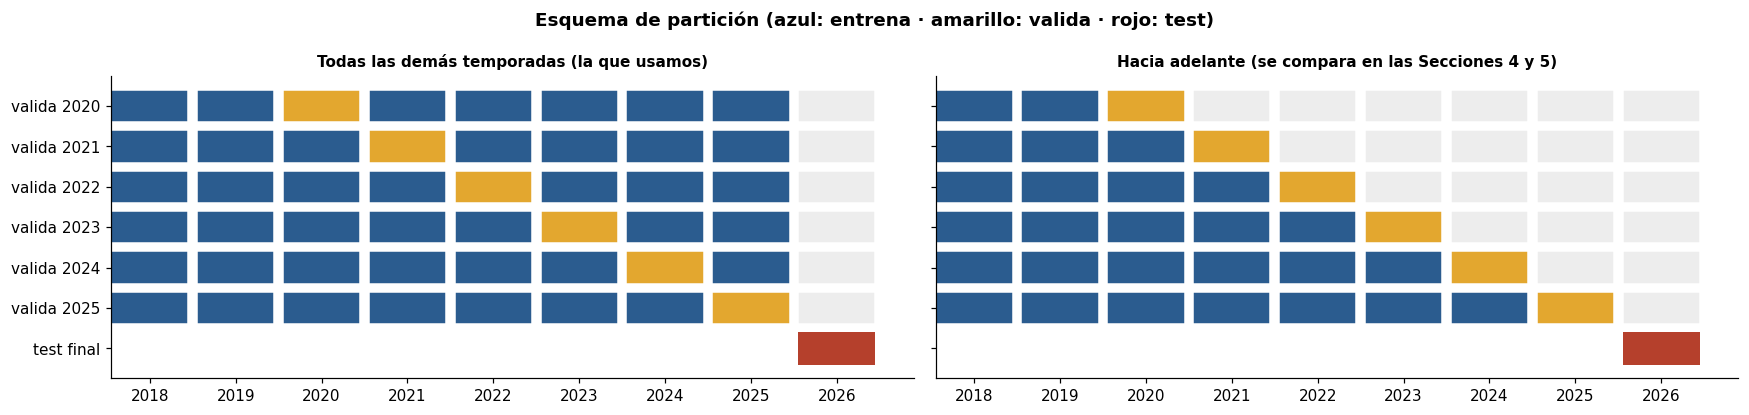

In [ ]:
ANIO_VALIDACION = 2025
ANIO_TEST = 2026
PRIMER_ANIO_VALIDACION = 2020

tr = df[df["Year"] < ANIO_TEST].reset_index(drop=True)
te = df[df["Year"] >= ANIO_TEST].reset_index(drop=True)
X_tr, y_tr = tr[ENTRADA], tr["Puesto_01"]
X_te, y_te = te[ENTRADA], te["Puesto_01"]


def pliegues_por_temporada(anios, desde=PRIMER_ANIO_VALIDACION, hacia_adelante=False):
    # Valida con cada temporada; entrena con todas las demás o, hacia adelante, solo con las anteriores.
    pliegues = []
    for a in sorted(anios.unique()):
        if a >= desde:
            entrena = anios < a if hacia_adelante else anios != a
            pliegues.append((f"valida {a}", np.where(entrena)[0], np.where(anios == a)[0]))
    return pliegues


PLIEGUES = pliegues_por_temporada(tr["Year"])
PLIEGUES_ADELANTE = pliegues_por_temporada(tr["Year"], hacia_adelante=True)
PLIEGUE_VAL = f"valida {ANIO_VALIDACION}"


def rango(anios):
    anios = sorted(set(anios))
    lo, hi = anios[0], anios[-1]
    faltan = sorted(set(range(lo, hi + 1)) - set(anios))
    return (f"{lo}–{hi}" if lo != hi else str(lo)) + (f" sin {faltan[0]}" if faltan else "")


def resumen_parte(d, parte, uso):
    return {"Parte": parte, "Temporadas": rango(d.Year), "Carreras": d.Carrera.nunique(),
            "Filas": len(d), "Para qué": uso}


particion = pd.DataFrame([
    resumen_parte(tr, "Entrenamiento y validación", "Validación cruzada: cada temporada se valida con todas las demás"),
    resumen_parte(tr[tr.Year >= PRIMER_ANIO_VALIDACION], "  temporadas que se validan",
                  "Elegir modelo, hiperparámetros y columnas"),
    resumen_parte(tr, "Entrenamiento del modelo final", "Ajustar el modelo elegido"),
    resumen_parte(te, "Test", "Medir una sola vez el modelo final"),
]).set_index("Parte")
mostrar(particion, "Partición entrenamiento / validación / test", texto_largo=True)

pliegues_tabla = pd.DataFrame([
    {"Pliegue": nombre,
     "Todas las demás: entrena con": rango(tr.Year.iloc[a]),
     "Todas las demás: filas": len(a),
     "Hacia adelante: entrena con": rango(tr.Year.iloc[a2]),
     "Hacia adelante: filas": len(a2),
     "Carreras validación": tr.Carrera.iloc[b].nunique(), "Filas validación": len(b)}
    for (nombre, a, b), (_, a2, _) in zip(PLIEGUES, PLIEGUES_ADELANTE)
]).set_index("Pliegue")
mostrar(pliegues_tabla, "Pliegues de la validación cruzada por temporada (los dos esquemas)")

# Ninguna carrera queda de los dos lados en ningún pliegue.
assert all(not set(tr.Carrera.iloc[a]) & set(tr.Carrera.iloc[b]) for _, a, b in PLIEGUES + PLIEGUES_ADELANTE)
assert not set(tr.Carrera) & set(te.Carrera)

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), sharey=True)
anios = sorted(df["Year"].unique())
for ax, (titulo, pliegues) in zip(axes, [("Todas las demás temporadas (la que usamos)", PLIEGUES),
                                         ("Hacia adelante (se compara en las Secciones 4 y 5)", PLIEGUES_ADELANTE)]):
    for i, (nombre, a, b) in enumerate(pliegues):
        ent, val = set(tr.Year.iloc[a]), set(tr.Year.iloc[b])
        for y_ in anios:
            color = AZUL if y_ in ent else AMARILLO if y_ in val else "#EDEDED"
            ax.barh(i, 0.9, left=y_ - 0.45, color=color, edgecolor="white")
    ax.barh(len(pliegues), 0.9, left=ANIO_TEST - 0.45, color=ROJO)
    ax.set_yticks(range(len(pliegues) + 1), [n for n, _, _ in pliegues] + ["test final"])
    ax.set_xticks(anios)
    ax.grid(False)
    ax.set_title(titulo, fontsize=10)
axes[0].invert_yaxis()
fig.suptitle("Esquema de partición (azul: entrena · amarillo: valida · rojo: test)", fontweight="bold")
plt.tight_layout()
plt.show()

### La función que valida

Todo modelo se mide con la misma función: entrena una copia en cada pliegue, predice la temporada que
quedó afuera y calcula las métricas. Se resume con la **media y el desvío entre pliegues**.

In [ ]:
def validar(modelo, datos=tr, pliegues=PLIEGUES, entrada=ENTRADA, por_carrera=True):
    # Entrena una copia del modelo en cada pliegue y mide sobre la parte de validación.
    filas = []
    for nombre, a, b in pliegues:
        m = clone(modelo).fit(datos.iloc[a][entrada], datos.iloc[a]["Puesto_01"])
        pred = m.predict(datos.iloc[b][entrada])
        filas.append({"Pliegue": nombre, **medir(pred, datos.iloc[b], por_carrera)})
    return pd.DataFrame(filas).set_index("Pliegue")


def resumir(res, nombre):
    fila = {"Modelo": nombre,
            "MAE · media": res["MAE (puestos)"].mean(),
            "MAE · desvío": res["MAE (puestos)"].std(),
            f"MAE · {ANIO_VALIDACION}": res["MAE (puestos)"].get(PLIEGUE_VAL, np.nan),
            "MAE sin abandonos": res["MAE sin abandonos"].mean(),
            "RMSE (puestos)": res["RMSE (puestos)"].mean(),
            "RMSE sin abandonos": res["RMSE sin abandonos"].mean()}
    for m in METRICAS[2:]:
        fila[m] = res[m].mean()
    return fila


def tabla_resumen(resultados):
    return pd.DataFrame([resumir(r, n) for n, r in resultados.items()]).set_index("Modelo")

## Sección 3: El pipeline, el piso y la grilla

### El pipeline

Todo lo que se calcula a partir de los datos va adentro del objeto que se entrena, en este orden:

1. **Desgaste:** `FP_Desgaste_{SOFT,MED} = (vuelta promedio − mejor vuelta) / mejor vuelta × 100`,
   con las columnas en segundos. Es una cuenta por fila, pero va adentro igual: la aplicación recibe
   las vueltas y el modelo calcula el desgaste solo.
2. **Grilla:** los nulos (largada desde boxes) se completan con **21**, detrás de una grilla de 20,
   que es donde larga ese piloto.
3. **Tiempos DBT** (Q_Best y las tres mejores vueltas): `log(1 + x)`, que es lo que pidió H2 para
   Q_Best y lo que mostró H5 para las vueltas de prácticas (colas de hasta 90%). Después, mediana
   para los nulos y una **columna indicadora de nulo**: que un piloto no tenga vuelta con HARD
   (54% de las filas) también es información.
4. **El resto** (distancia al líder y desgaste): mediana e indicadora de nulo. La distancia al líder
   falta en la primera fecha de cada temporada para todos los pilotos a la vez, así que la mediana
   no cambia el orden dentro de esa carrera.
5. **Solo en los modelos lineales:** los **términos cruzados** mejor vuelta × desgaste (SOFT y MED) y
   el escalado. H7 mostró que el desgaste solo no predice y H6 que cambia el peso de cada mejor
   vuelta: un lineal sin términos cruzados no puede representar eso. A los árboles no les hace falta
   porque combinan columnas por su cuenta.

Las medianas, el escalado y las categorías se aprenden en el `fit`, o sea, solo con las filas de
entrenamiento de cada pliegue. Nada se calcula sobre el dataset entero.

Hay un paso más que está programado pero **apagado**: pesar la distancia al líder por la fecha del
campeonato (`(ronda − 1) / 20`), con la idea de que en las primeras fechas la distancia dice poco.
Se probó y empeora el error en la validación cruzada; la medición está en la Sección 6.

In [ ]:
class Desgaste(BaseEstimator, TransformerMixin):
    # Calcula FP_Desgaste_SOFT y FP_Desgaste_MED con las vueltas en segundos y descarta esas columnas.
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for c in ["SOFT", "MED"]:
            mejor, media = X[f"FP_LapTime_min_{c}_ABS"], X[f"FP_LapTime_mean_{c}_ABS"]
            X[f"FP_Desgaste_{c}"] = (media - mejor) / mejor * 100
        return X.drop(columns=ABS_DESGASTE)


class PesarDistanciaLider(BaseEstimator, TransformerMixin):
    # Multiplica la distancia al líder por (ronda - 1) / 20. Probado en la Sección 6; apagado por defecto.
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        if "DriverPoints_Before_DBT_%" in X.columns and "Carrera" in X.columns:
            rondas = X["Carrera"].str.extract(r"-R(\d+)")[0].astype(float)
            X["DriverPoints_Before_DBT_%"] = X["DriverPoints_Before_DBT_%"] * (rondas - 1).clip(lower=0) / 20.0
        return X


class Interacciones(BaseEstimator, TransformerMixin):
    # Agrega mejor vuelta × desgaste para SOFT y MED, si las dos columnas están.
    PARES = [("FP_LapTime_min_SOFT_DBT_%", "FP_Desgaste_SOFT"),
             ("FP_LapTime_min_MED_DBT_%", "FP_Desgaste_MED")]

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for a, b in self.PARES:
            if a in X.columns and b in X.columns:
                X[f"{a} × {b}"] = X[a] * X[b]
        return X


class ReglaGrilla(BaseEstimator, RegressorMixin):
    # Referencia sin aprendizaje: el puntaje es la posición de largada.
    def fit(self, X, y=None):
        self.ajustado_ = True
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float)[:, 0] / 21


def armar_preprocesador(columnas=COLUMNAS_BASE, lineal=True, interacciones=True,
                        log_cols=TIEMPOS_DBT, categoricas=(), pesar_distancia=False):
    grilla = [c for c in columnas if c == "Q_GridPosition"]
    con_log = [c for c in columnas if c in log_cols]
    cat = [c for c in columnas if c in categoricas]
    resto = [c for c in columnas if c not in grilla + con_log + cat]

    bloques = []
    if grilla:
        bloques.append(("grilla", SimpleImputer(strategy="constant", fill_value=21), grilla))
    if con_log:
        bloques.append(("tiempos", Pipeline([
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("imputar", SimpleImputer(strategy="median", add_indicator=True)),
        ]), con_log))
    if resto:
        bloques.append(("resto", SimpleImputer(strategy="median", add_indicator=True), resto))
    if cat:
        bloques.append(("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))

    pasos = [("desgaste", Desgaste())]
    if pesar_distancia:
        pasos.append(("peso_distancia", PesarDistanciaLider()))
    pasos.append(("columnas", ColumnTransformer(bloques, remainder="drop", verbose_feature_names_out=False)))
    if lineal:
        if interacciones:
            pasos.append(("interacciones", Interacciones()))
        pasos.append(("escala", StandardScaler()))
    return pasos


def armar_pipeline(modelo, **cfg):
    return Pipeline(armar_preprocesador(**cfg) + [("modelo", modelo)])


armar_pipeline(LinearRegression())

Pipeline(steps=[('desgaste', Desgaste()),
                ('columnas',
                 ColumnTransformer(transformers=[('grilla',
                                                  SimpleImputer(fill_value=21,
                                                                strategy='constant'),
                                                  ['Q_GridPosition']),
                                                 ('tiempos',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('imputar',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median'))]),
                                                  ['Q_Best_seconds_DBT_%',
                                                   'FP_LapTime_min_SOFT_DBT_%',
                                                   'FP_LapTime_min_MED_DBT_%',
                                                   'FP_LapTime_min_HARD_DBT_%']),
                                                 ('resto',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median'),
                                                  ['DriverPoints_Before_DBT_%',
                                                   'FP_Desgaste_SOFT',
                                                   'FP_Desgaste_MED'])],
                                   verbose_feature_names_out=False)),
                ('interacciones', Interacciones()),
                ('escala', StandardScaler()), ('modelo', LinearRegression())])

### El piso y la referencia de la grilla

Dos referencias, medidas con los mismos pliegues que todo lo demás:

- **El piso de la consigna:** un `DummyRegressor` que predice el mismo puntaje para todos (la media
  del entrenamiento). Al ordenar, todos empatan en la mitad de la tabla. Como no elige a nadie, las
  métricas de zona de puntos, podio y ganador no se pueden calcular y quedan vacías.
- **La grilla sola:** el puesto predicho es el de largada. No aprende nada, pero es lo que cualquiera
  diría sin modelo. **Es la referencia que importa:** si el modelo no le gana a la grilla, no dice
  nada que la grilla no dijera.

,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE (puestos),RMSE sin abandonos,Mediana del error absoluto,Acierto ±2 puestos (%),Spearman por carrera,Acierto zona de puntos (%),Acierto podio (%),Acierto ganador (%)
Modelo,,,,,,,,,,,,
Piso: Dummy (media),"4,996","0,006","4,989","4,361","5,762","5,059","5,000","20,085",—,"52,632",—,—
Referencia: grilla sola,"3,487","0,400","3,359","2,460","4,984","3,536","2,500","51,891","0,623","76,833","67,672","55,333"


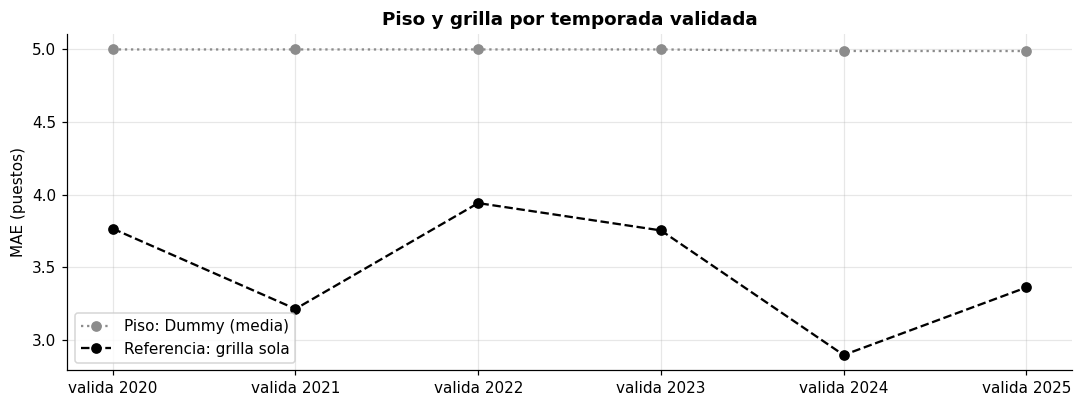

In [ ]:
PISO, GRILLA = "Piso: Dummy (media)", "Referencia: grilla sola"
resultados_cv = {}
resultados_cv[PISO] = validar(armar_pipeline(DummyRegressor(strategy="mean")))
resultados_cv[GRILLA] = validar(armar_pipeline(ReglaGrilla(), columnas=["Q_GridPosition"], lineal=False))

mostrar(tabla_resumen(resultados_cv), "Piso y referencia (validación cruzada por temporada)", decimales=3)

fig, ax = plt.subplots(figsize=(10, 3.8))
for nombre, color, linea in [(PISO, GRIS, ":"), (GRILLA, "black", "--")]:
    r = resultados_cv[nombre]["MAE (puestos)"]
    ax.plot(r.index, r.values, marker="o", color=color, linestyle=linea, label=nombre)
ax.set_ylabel("MAE (puestos)")
ax.set_title("Piso y grilla por temporada validada")
ax.legend()
plt.tight_layout()
plt.show()

El dummy erra unos 5 puestos, que es lo esperable de poner a todos en la mitad de la tabla. La grilla
sola ya baja ese error a cerca de 3,5 puestos: la mayor parte de lo que se puede saber antes de la
carrera ya está en la clasificación. El desvío de la grilla entre temporadas muestra que hay años
mucho más previsibles que otros, y es contra ese desvío que se van a leer las diferencias entre
modelos.

## Sección 4: Qué le pasa al número según cómo se parte

Para mostrar por qué se valida por temporada, se mide el lineal con cuatro formas de partir el
entrenamiento (2018–2025):

- **Al azar por filas** (`KFold` mezclado): un GP queda repartido entre entrenamiento y validación,
  y se mezclan todas las temporadas.
- **Por carrera** (`GroupKFold` con la carrera como grupo): cada GP entero de un lado, pero con
  temporadas mezcladas.
- **Por temporada, todas las demás** (la que usamos).
- **Por temporada, hacia adelante.**

Se mide también el lineal **con `TeamId`**, la columna que el EDA sacó por cambiar de fuerza con la
era. Si la sospecha del EDA era correcta, `TeamId` tiene que verse útil cuando se mezclan
temporadas y dejar de serlo cuando se valida con una temporada entera que el modelo no vio.

En el reparto al azar por filas no se puede ordenar dentro del GP (en validación quedan cuatro o
cinco pilotos de cada carrera), así que la comparación entre los cuatro esquemas se hace con el
**MAE directo**. Para los que dejan las carreras enteras se muestra también el MAE en puestos.

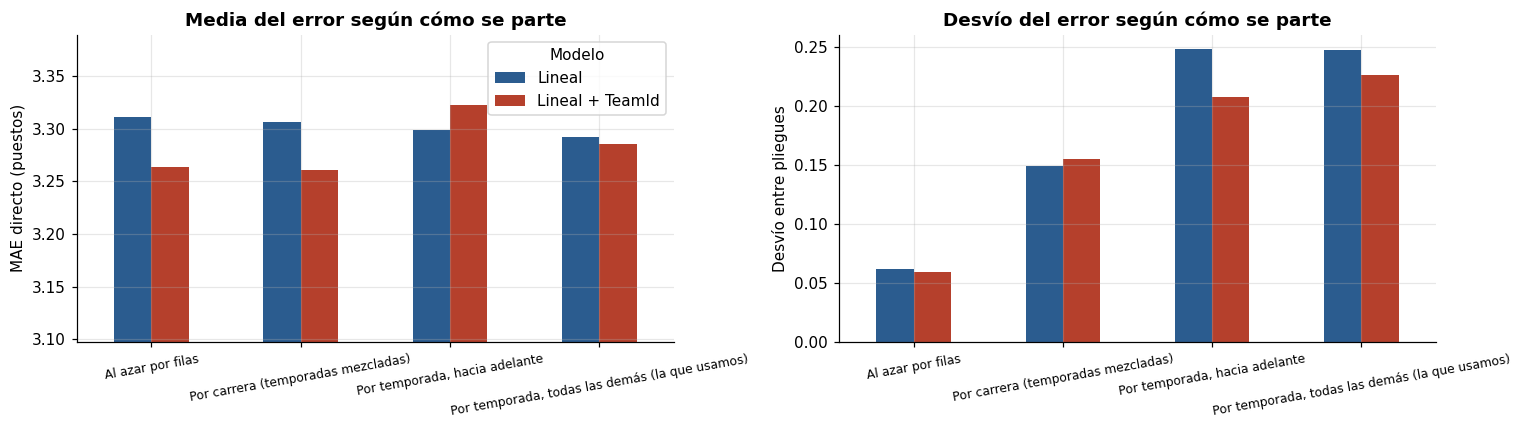

In [ ]:
pliegues_azar = [(f"azar {i}", a, b) for i, (a, b) in
                 enumerate(KFold(6, shuffle=True, random_state=SEMILLA).split(tr))]
pliegues_carrera = [(f"carrera {i}", a, b) for i, (a, b) in
                    enumerate(GroupKFold(6).split(tr, groups=tr["Carrera"]))]

ESQUEMAS = {
    "Al azar por filas": (pliegues_azar, False),
    "Por carrera (temporadas mezcladas)": (pliegues_carrera, True),
    "Por temporada, todas las demás (la que usamos)": (PLIEGUES, True),
    "Por temporada, hacia adelante": (PLIEGUES_ADELANTE, True),
}
MODELOS_ESQUEMA = {
    "Lineal": armar_pipeline(LinearRegression()),
    "Lineal + TeamId": armar_pipeline(LinearRegression(), columnas=COLUMNAS_BASE + ["TeamId"],
                                      categoricas=("TeamId",)),
}

filas = []
for esquema, (pliegues, por_carrera) in ESQUEMAS.items():
    for nombre, pipe in MODELOS_ESQUEMA.items():
        res = validar(pipe, pliegues=pliegues, por_carrera=por_carrera)
        filas.append({"Esquema": esquema, "Modelo": nombre,
                      "MAE directo · media": res["MAE directo"].mean(),
                      "MAE directo · desvío": res["MAE directo"].std(),
                      "MAE (puestos) · media": res["MAE (puestos)"].mean()})
tabla_esquemas = pd.DataFrame(filas).set_index(["Esquema", "Modelo"])
mostrar(tabla_esquemas, "El mismo modelo medido con cuatro formas de partir los datos", decimales=3)

media = tabla_esquemas["MAE directo · media"].unstack()
desvio = tabla_esquemas["MAE directo · desvío"].unstack()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
media.plot.bar(ax=axes[0], rot=10, color=[AZUL, ROJO])
axes[0].set_xlabel("")
axes[0].set_ylabel("MAE directo (puestos)")
axes[0].set_title("Media del error según cómo se parte")
axes[0].set_ylim(media.min().min() * 0.95, media.max().max() * 1.02)
axes[0].tick_params(axis="x", labelsize=8)
desvio.plot.bar(ax=axes[1], rot=10, color=[AZUL, ROJO], legend=False)
axes[1].set_xlabel("")
axes[1].set_ylabel("Desvío entre pliegues")
axes[1].set_title("Desvío del error según cómo se parte")
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

Qué le pasa al número si los pedazos se arman al azar: **la media casi no cambia, pero el desvío se
achica a menos de un tercio.** Al azar, cada pedazo tiene un poco de cada temporada y todos se
parecen; por temporada, aparece que hay años mucho más difíciles que otros. El riesgo de partir al
azar no es tanto un número más lindo como una comparación engañosa: con un desvío tan chico,
diferencias entre modelos que son ruido de temporada parecerían reales.

Lo de `TeamId` es la otra mitad, y es la fuga que una validación al azar no deja ver. Al azar y por
carrera, agregarlo baja el error, y si hubiéramos validado así lo habríamos dejado adentro. Por
temporada, en el MAE en puestos (la métrica que decide), deja de ayudar: la fuerza de un equipo
aprendida en otras temporadas no sirve para la que se valida. Es lo que el EDA sospechaba, y por eso
queda afuera.

Entre los dos esquemas por temporada la diferencia es chica, que es lo que permite usar "todas las
demás" sin que el número cambie de forma importante.

### ¿Cuántas temporadas hacia atrás sirven?

Si la fuerza de los equipos cambia con la era, puede que las temporadas viejas confundan más de lo
que enseñan. Se entrena el lineal con ventanas cada vez más largas hacia atrás y se valida siempre
con la misma temporada (2025, y 2024 como control).

Valida,2024,2025
Temporadas de entrenamiento,,
1,"2,910","3,373"
2,"2,839","3,368"
3,"2,797","3,351"
4,"2,785","3,351"
5,"2,781","3,368"
6,"2,789","3,368"
7,—,"3,333"


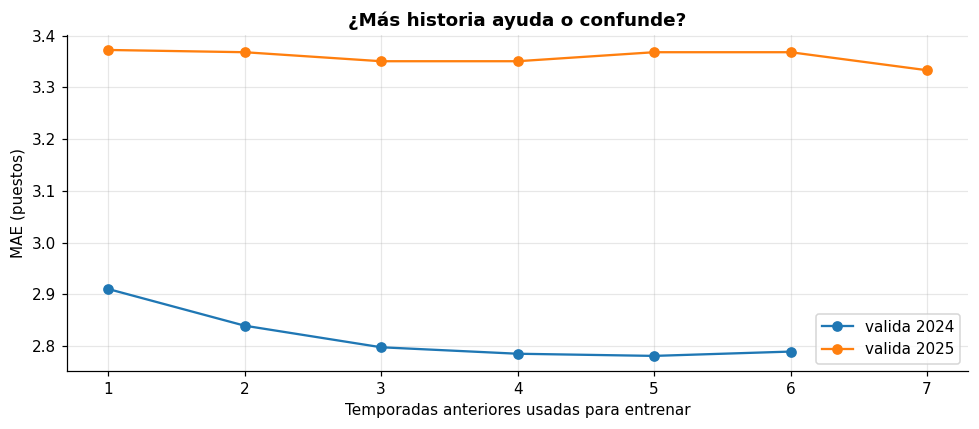

In [ ]:
filas = []
for anio_val in [ANIO_VALIDACION - 1, ANIO_VALIDACION]:
    val = tr[tr["Year"] == anio_val]
    for n_temp in range(1, anio_val - tr["Year"].min() + 1):
        ent = tr[(tr["Year"] < anio_val) & (tr["Year"] >= anio_val - n_temp)]
        m = armar_pipeline(LinearRegression()).fit(ent[ENTRADA], ent["Puesto_01"])
        filas.append({"Valida": anio_val, "Temporadas de entrenamiento": n_temp,
                      "Desde": anio_val - n_temp, **medir(m.predict(val[ENTRADA]), val)})
curva_temp = pd.DataFrame(filas)
mostrar(curva_temp.pivot(index="Temporadas de entrenamiento", columns="Valida", values="MAE (puestos)"),
        "MAE según cuántas temporadas anteriores se usan para entrenar", decimales=3)

fig, ax = plt.subplots(figsize=(9, 4))
for anio_val, g in curva_temp.groupby("Valida"):
    ax.plot(g["Temporadas de entrenamiento"], g["MAE (puestos)"], marker="o", label=f"valida {anio_val}")
ax.set_xlabel("Temporadas anteriores usadas para entrenar")
ax.set_ylabel("MAE (puestos)")
ax.set_title("¿Más historia ayuda o confunde?")
ax.legend()
plt.tight_layout()
plt.show()

La curva es casi plana: sumar temporadas viejas no empeora el error. Como el modelo no usa columnas
que identifiquen equipos o pilotos, lo que aprende de 2018 sigue sirviendo en 2025. Por eso el modelo
final se entrena con todas las temporadas disponibles.

## Sección 5: Comparación de modelos

Primero el modelo simple, una **regresión lineal** con el pipeline completo. Es la referencia contra
la que se justifica cualquier otro. Después, tres familias más sobre las mismas columnas y con los
mismos pliegues: un **árbol**, un **bosque** y un **boosting**, con hiperparámetros razonables de
partida (en la Sección 6 se ajustan todos antes de elegir).

La comparación se hace **pliegue a pliegue**: para cada modelo se calcula la diferencia de MAE con el
lineal en cada temporada validada, y se mira su media y su desvío. La regla, fijada antes de correr el
primer modelo: **un modelo más complejo reemplaza al lineal solo si le gana por más que el desvío de
esa diferencia.** Si no, se queda el lineal. Se elige con esta regla y con la validación cruzada,
nunca con el test.

In [ ]:
CONSTRUCTORES = {
    "Lineal": lambda **cfg: armar_pipeline(LinearRegression(), **cfg),
    "Árbol": lambda **cfg: armar_pipeline(
        DecisionTreeRegressor(max_depth=5, min_samples_leaf=30, random_state=SEMILLA), **{**cfg, "lineal": False}),
    "Bosque": lambda **cfg: armar_pipeline(
        RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=0.5,
                              n_jobs=-1, random_state=SEMILLA), **{**cfg, "lineal": False}),
    "Boosting": lambda **cfg: armar_pipeline(
        HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, max_depth=4,
                                      min_samples_leaf=30, random_state=SEMILLA), **{**cfg, "lineal": False}),
}
CLASICOS = list(CONSTRUCTORES)

for nombre in CLASICOS:
    resultados_cv[nombre] = validar(CONSTRUCTORES[nombre]())

mostrar(tabla_resumen(resultados_cv),
        f"Comparación de modelos (validación cruzada por temporada, {len(PLIEGUES)} pliegues)", decimales=3)


def diferencias_contra(resultados, base, nombres):
    ref = resultados[base]["MAE (puestos)"]
    filas = []
    for n in nombres:
        dif = resultados[n]["MAE (puestos)"] - ref
        filas.append({"Modelo": n, f"Diferencia con {base.lower()} · media": dif.mean(),
                      "Diferencia · desvío": dif.std(),
                      "Pliegues en que gana": f"{int((dif < 0).sum())} de {len(dif)}",
                      f"Diferencia en {ANIO_VALIDACION}": dif.get(PLIEGUE_VAL, np.nan),
                      "Gana por más que el desvío": "sí" if -dif.mean() > dif.std() else "no"})
    return pd.DataFrame(filas).set_index("Modelo")


mostrar(diferencias_contra(resultados_cv, "Lineal", CLASICOS[1:]),
        "Diferencia pliegue a pliegue contra el lineal (negativo = mejor que el lineal)", decimales=3)
mostrar(diferencias_contra(resultados_cv, GRILLA, CLASICOS),
        "Diferencia pliegue a pliegue contra la grilla sola (negativo = mejor que la grilla)", decimales=3)

,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE (puestos),RMSE sin abandonos,Mediana del error absoluto,Acierto ±2 puestos (%),Spearman por carrera,Acierto zona de puntos (%),Acierto podio (%),Acierto ganador (%)
Modelo,,,,,,,,,,,,
Piso: Dummy (media),"4,996","0,006","4,989","4,361","5,762","5,059","5,000","20,085",—,"52,632",—,—
Referencia: grilla sola,"3,487","0,400","3,359","2,460","4,984","3,536","2,500","51,891","0,623","76,833","67,672","55,333"
Lineal,"3,325","0,361","3,333","2,242","4,744","3,177","2,250","53,184","0,658","78,137","65,982","56,276"
Árbol,"3,462","0,318","3,423","2,388","4,827","3,305","2,417","47,441","0,643","79,017","67,676","34,952"
Bosque,"3,342","0,296","3,281","2,206","4,745","3,139","2,167","52,272","0,659","78,026","67,571","50,429"
Boosting,"3,490","0,308","3,595","2,384","4,878","3,314","2,250","51,212","0,639","76,554","63,774","37,248"


,Diferencia con lineal · media,Diferencia · desvío,Pliegues en que gana,Diferencia en 2025,Gana por más que el desvío
Modelo,,,,,
Árbol,"0,137","0,066",0 de 6,"0,089",no
Bosque,"0,017","0,077",3 de 6,"-0,052",no
Boosting,"0,165","0,096",0 de 6,"0,261",no


,Diferencia con referencia: grilla sola · media,Diferencia · desvío,Pliegues en que gana,Diferencia en 2025,Gana por más que el desvío
Modelo,,,,,
Lineal,"-0,162","0,163",6 de 6,"-0,026",no
Árbol,"-0,025","0,173",2 de 6,"0,063",no
Bosque,"-0,145","0,160",5 de 6,"-0,078",no
Boosting,"0,003","0,170",3 de 6,"0,235",no


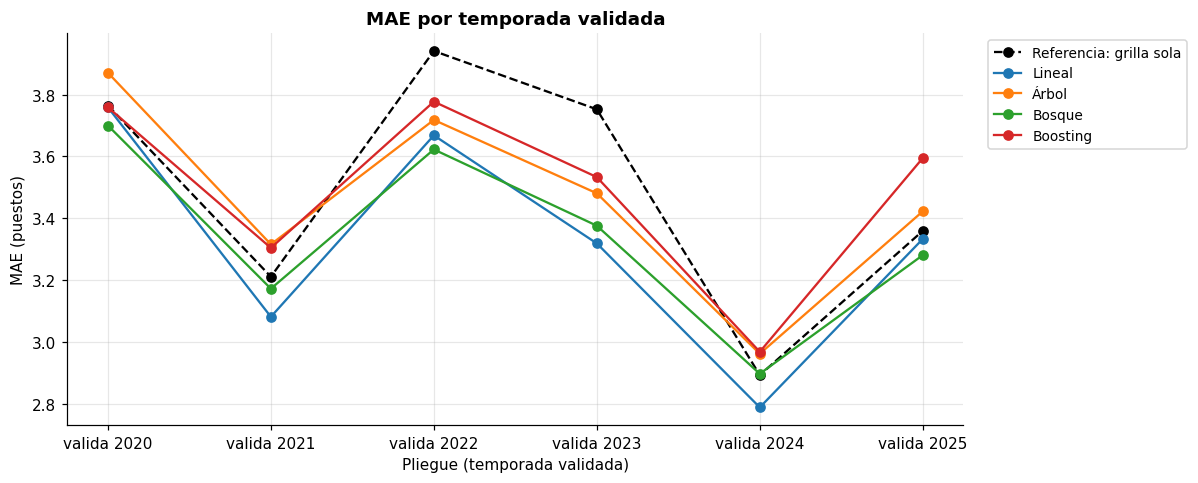

In [ ]:
def grafico_por_pliegue(resultados, nombres, titulo):
    fig, ax = plt.subplots(figsize=(11, 4.5))
    estilos = {PISO: (GRIS, ":"), GRILLA: ("black", "--")}
    for n in nombres:
        color, linea = estilos.get(n, (None, "-"))
        r = resultados[n]["MAE (puestos)"]
        ax.plot(r.index, r.values, marker="o", linestyle=linea, color=color, label=n)
    ax.set_xlabel("Pliegue (temporada validada)")
    ax.set_ylabel("MAE (puestos)")
    ax.set_title(titulo)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()


def grafico_metricas(resultados, nombres, titulo):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax, m in zip(axes.ravel(), METRICAS):
        medias = [resultados[n][m].mean() for n in nombres]
        desvios = [resultados[n][m].std() for n in nombres]
        colores = [GRIS if n in (PISO, GRILLA) else AZUL for n in nombres]
        ax.barh(nombres, medias, xerr=desvios, color=colores, capsize=2)
        ax.set_title(m, fontsize=10)
        ax.invert_yaxis()
        ax.tick_params(axis="y", labelsize=8)
        validos = [v for v in medias if pd.notna(v)]
        if validos and "Acierto" not in m:
            ax.set_xlim(min(validos) * 0.9, max(validos) * 1.05)
    fig.suptitle(titulo, fontweight="bold")
    plt.tight_layout()
    plt.show()


grafico_por_pliegue(resultados_cv, [GRILLA] + CLASICOS, "MAE por temporada validada")

### Tres enfoques alternativos

Además de las familias, se prueban tres formas de modelar que podían tener sentido para este problema,
con los mismos pliegues y la misma regla contra el lineal.

**Modelos por zona de grilla solapadas.** Lo que define el resultado no tiene por qué ser igual para
el que larga adelante que para el que larga en el fondo. Se entrena **un lineal por zona de la
grilla** (1–8, 5–14 y 11–22). Las zonas se solapan: un piloto que larga 6.º entra en el modelo de 1–8
y en el de 5–14, y su predicción es el promedio de los dos. Sin solapamiento, la predicción podría
saltar justo en el borde entre zonas.

**Ranking por carrera (LambdaMART).** Los modelos anteriores aprenden el puntaje de cada piloto por
separado y el orden aparece recién al final. Un modelo de ranking aprende directamente a **ordenar a
los pilotos de una misma carrera entre sí**. Se usa `LGBMRanker` con objetivo `lambdarank`, que
optimiza NDCG y le da más peso a acertar los primeros puestos. La relevancia de cada piloto es su
puesto invertido, con ganancia lineal (la exponencial de LightGBM, con 20 niveles, haría que solo se
ocupe del ganador).

**Promedio lineal + bosque.** En lugar de elegir, se promedian los dos clásicos que más se acercan
entre sí y que se equivocan de forma distinta (uno es recto y el otro no).

In [ ]:
class PorZonaDeGrilla(BaseEstimator, RegressorMixin):
    # Un modelo por zona de grilla; la predicción promedia las zonas que contienen al piloto.
    def __init__(self, modelo=None, ventanas=((1, 8), (5, 14), (11, 22))):
        self.modelo = modelo
        self.ventanas = ventanas

    def _grilla(self, X):
        return X["Q_GridPosition"].fillna(21).to_numpy()

    def fit(self, X, y):
        g, y = self._grilla(X), np.asarray(y)
        self.modelos_ = []
        for lo, hi in self.ventanas:
            m = (g >= lo) & (g <= hi)
            self.modelos_.append(clone(self.modelo).fit(X[m], y[m]))
        return self

    def predict(self, X):
        g = self._grilla(X)
        suma, cuenta = np.zeros(len(X)), np.zeros(len(X))
        for (lo, hi), mod in zip(self.ventanas, self.modelos_):
            m = (g >= lo) & (g <= hi)
            if m.any():
                suma[m] += mod.predict(X[m])
                cuenta[m] += 1
        return suma / np.maximum(cuenta, 1)


class RankingPorCarrera(BaseEstimator, RegressorMixin):
    # LambdaMART agrupado por carrera. Devuelve un puntaje donde menor = mejor, como el resto.
    def __init__(self, preprocesador=None, n_estimators=300, learning_rate=0.05, num_leaves=15,
                 min_child_samples=30, random_state=SEMILLA):
        self.preprocesador = preprocesador
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.num_leaves = num_leaves
        self.min_child_samples = min_child_samples
        self.random_state = random_state

    def fit(self, X, y):
        self.prep_ = clone(self.preprocesador).fit(X, y)
        Xt = np.asarray(self.prep_.transform(X), dtype=float)
        carrera = X["Carrera"].to_numpy()
        inicios = np.flatnonzero(np.r_[True, carrera[1:] != carrera[:-1]])
        grupos = np.diff(np.r_[inicios, len(carrera)])
        relevancia = np.rint((1 - np.asarray(y)) * 20).astype(int)
        self.ranker_ = LGBMRanker(objective="lambdarank", n_estimators=self.n_estimators,
                                  learning_rate=self.learning_rate, num_leaves=self.num_leaves,
                                  min_child_samples=self.min_child_samples,
                                  label_gain=list(range(31)), random_state=self.random_state, verbose=-1)
        self.ranker_.fit(Xt, relevancia, group=grupos)
        return self

    def predict(self, X):
        return -self.ranker_.predict(np.asarray(self.prep_.transform(X), dtype=float))


ZONAS = "Zonas de grilla solapadas"
RANKING = "Ranking por carrera"
PROMEDIO = "Promedio lineal + bosque"

CONSTRUCTORES[ZONAS] = lambda **cfg: PorZonaDeGrilla(armar_pipeline(LinearRegression(), **cfg))
CONSTRUCTORES[RANKING] = lambda **cfg: RankingPorCarrera(Pipeline(armar_preprocesador(**{**cfg, "lineal": False})))
CONSTRUCTORES[PROMEDIO] = lambda **cfg: VotingRegressor([
    ("lineal", CONSTRUCTORES["Lineal"](**cfg)), ("bosque", CONSTRUCTORES["Bosque"](**cfg))])

ALTERNATIVOS = [ZONAS, RANKING, PROMEDIO]
MODELOS = CLASICOS + ALTERNATIVOS
for nombre in ALTERNATIVOS:
    resultados_cv[nombre] = validar(CONSTRUCTORES[nombre]())

mostrar(tabla_resumen(resultados_cv),
        "Todos los modelos con hiperparámetros de partida (validación cruzada por temporada)", decimales=3)

tabla_dif = diferencias_contra(resultados_cv, "Lineal", MODELOS[1:])
mostrar(tabla_dif, "Todos los modelos: diferencia pliegue a pliegue contra el lineal (negativo = mejor)",
        decimales=3)

,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE (puestos),RMSE sin abandonos,Mediana del error absoluto,Acierto ±2 puestos (%),Spearman por carrera,Acierto zona de puntos (%),Acierto podio (%),Acierto ganador (%)
Modelo,,,,,,,,,,,,
Piso: Dummy (media),"4,996","0,006","4,989","4,361","5,762","5,059","5,000","20,085",—,"52,632",—,—
Referencia: grilla sola,"3,487","0,400","3,359","2,460","4,984","3,536","2,500","51,891","0,623","76,833","67,672","55,333"
Lineal,"3,325","0,361","3,333","2,242","4,744","3,177","2,250","53,184","0,658","78,137","65,982","56,276"
Árbol,"3,462","0,318","3,423","2,388","4,827","3,305","2,417","47,441","0,643","79,017","67,676","34,952"
Bosque,"3,342","0,296","3,281","2,206","4,745","3,139","2,167","52,272","0,659","78,026","67,571","50,429"
Boosting,"3,490","0,308","3,595","2,384","4,878","3,314","2,250","51,212","0,639","76,554","63,774","37,248"
Zonas de grilla solapadas,"3,309","0,349","3,242","2,192","4,726","3,142","2,167","53,861","0,661","78,372","67,154","54,088"
Ranking por carrera,"3,507","0,259","3,643","2,391","4,897","3,327","2,500","50,204","0,637","77,233","62,955","40,196"
Promedio lineal + bosque,"3,325","0,336","3,338","2,195","4,733","3,126","2,167","52,912","0,660","78,275","66,244","52,707"


,Diferencia con lineal · media,Diferencia · desvío,Pliegues en que gana,Diferencia en 2025,Gana por más que el desvío
Modelo,,,,,
Árbol,"0,137","0,066",0 de 6,"0,089",no
Bosque,"0,017","0,077",3 de 6,"-0,052",no
Boosting,"0,165","0,096",0 de 6,"0,261",no
Zonas de grilla solapadas,"-0,016","0,065",4 de 6,"-0,092",no
Ranking por carrera,"0,182","0,161",1 de 6,"0,309",no
Promedio lineal + bosque,"-0,000","0,040",2 de 6,"0,004",no


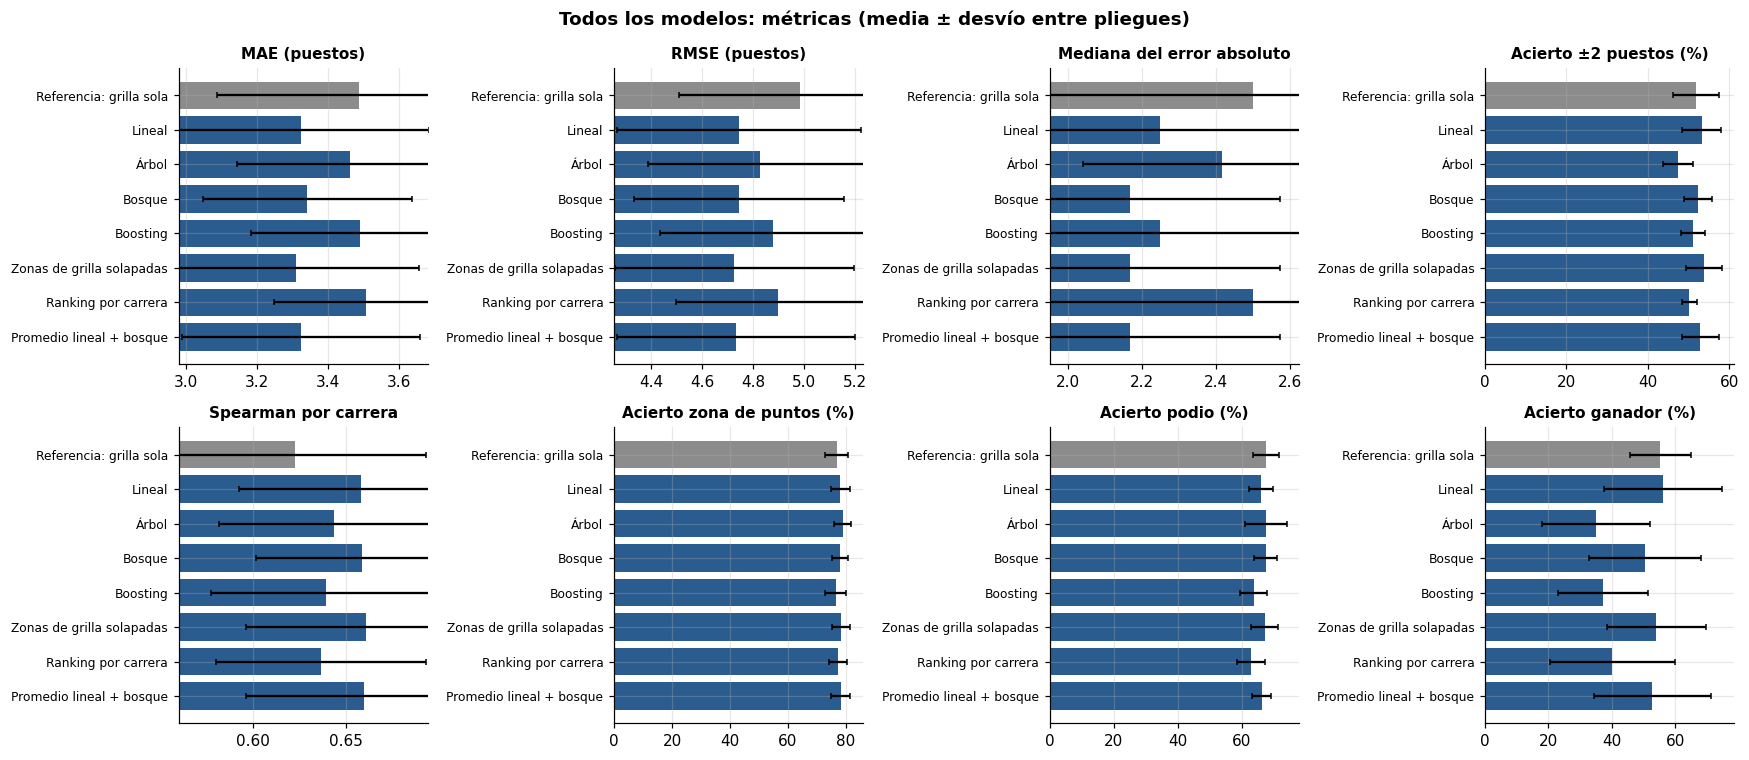

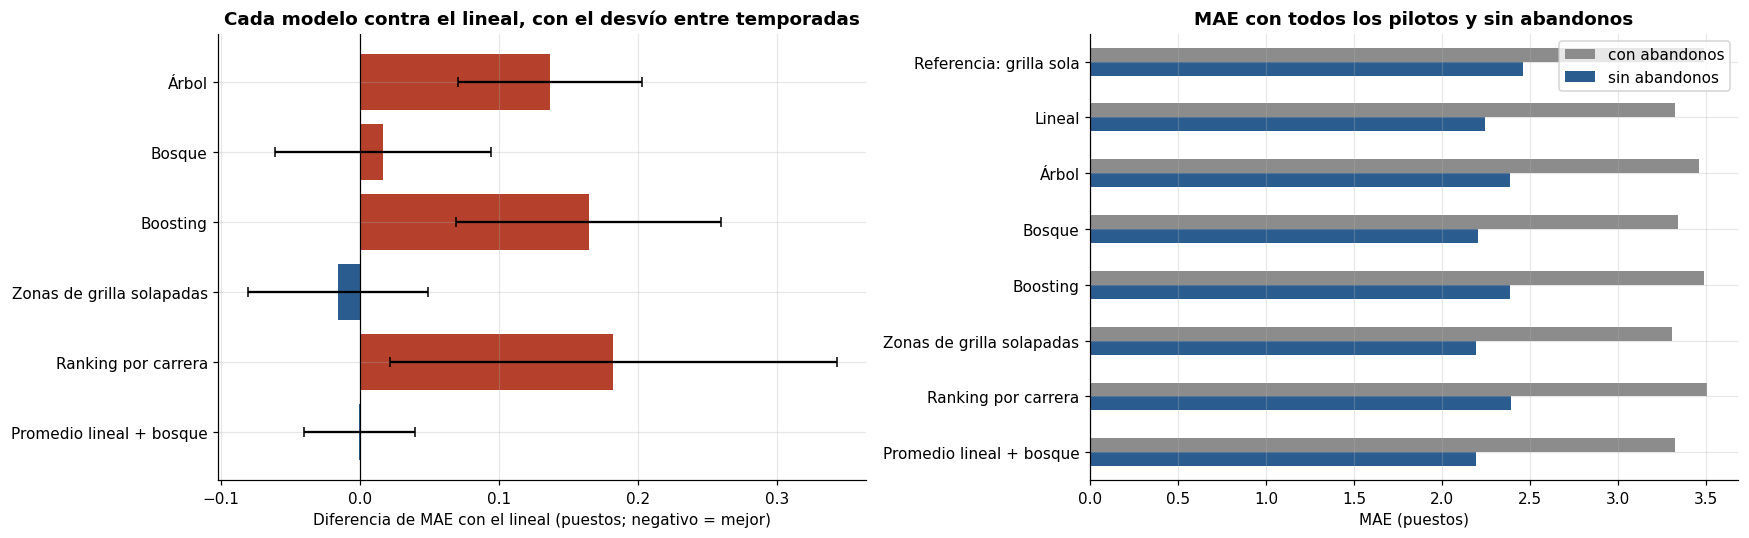

In [ ]:
grafico_metricas(resultados_cv, [GRILLA] + MODELOS, "Todos los modelos: métricas (media ± desvío entre pliegues)")

dif_plot = tabla_dif.iloc[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(16, 0.5 * len(dif_plot) + 2))
axes[0].barh(dif_plot.index, dif_plot.iloc[:, 0], xerr=dif_plot.iloc[:, 1], capsize=3,
             color=[AZUL if v < 0 else ROJO for v in dif_plot.iloc[:, 0]])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].invert_yaxis()
axes[0].set_xlabel("Diferencia de MAE con el lineal (puestos; negativo = mejor)")
axes[0].set_title("Cada modelo contra el lineal, con el desvío entre temporadas")

con_sin = pd.DataFrame({n: [resultados_cv[n]["MAE (puestos)"].mean(), resultados_cv[n]["MAE sin abandonos"].mean()]
                        for n in [GRILLA] + MODELOS}, index=["con abandonos", "sin abandonos"]).T
con_sin.plot.barh(ax=axes[1], color=[GRIS, AZUL])
axes[1].invert_yaxis()
axes[1].set_xlabel("MAE (puestos)")
axes[1].set_title("MAE con todos los pilotos y sin abandonos")
plt.tight_layout()
plt.show()

### ¿Cambia la elección con el esquema hacia adelante?

En la Sección 2 quedó dicho que usamos "todas las demás temporadas" aunque no imite del todo el uso.
Acá se repite la comparación de los cuatro clásicos con el esquema hacia adelante, con los mismos
hiperparámetros de partida y los mismos seis pliegues validados. Lo que importa es si cambia la
elección con la misma regla, y cuánto se mueve el error.

,Todas las demás · media,Todas las demás · desvío,Hacia adelante · media,Hacia adelante · desvío,Diferencia (adelante − todas)
Modelo,,,,,
Referencia: grilla sola,"3,487","0,400","3,487","0,400","0,000"
Lineal,"3,325","0,361","3,329","0,365","0,004"
Árbol,"3,462","0,318","3,562","0,223","0,101"
Bosque,"3,342","0,296","3,336","0,270","-0,005"
Boosting,"3,490","0,308","3,632","0,343","0,143"


,Diferencia con lineal · media,Diferencia · desvío,Pliegues en que gana,Diferencia en 2025,Gana por más que el desvío
Modelo,,,,,
Árbol,"0,234","0,205",0 de 6,"0,089",no
Bosque,"0,007","0,101",3 de 6,"-0,052",no
Boosting,"0,303","0,082",0 de 6,"0,261",no


Entre los clásicos, la regla elige: Lineal con todas las demás temporadas y Lineal hacia adelante.


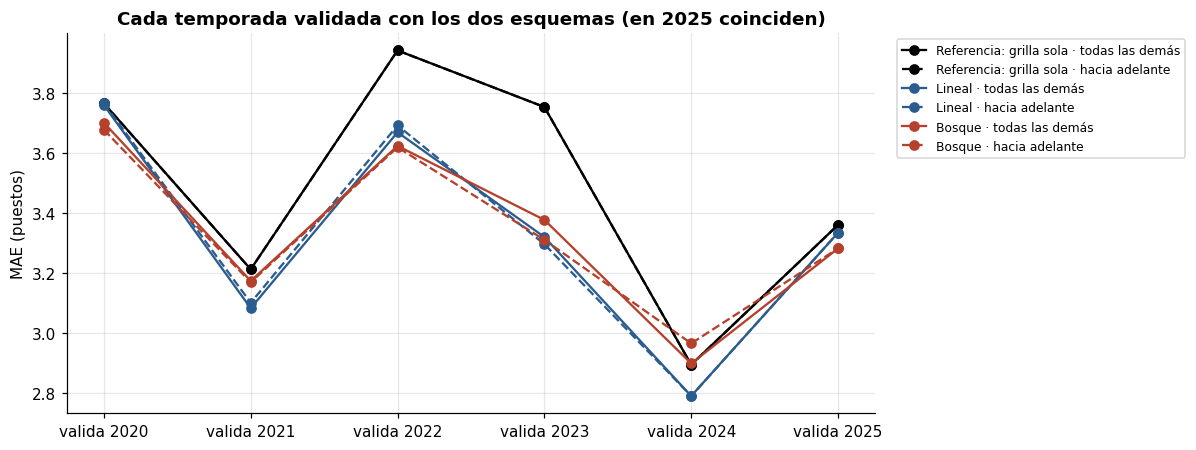

In [ ]:
COMPARADOS = [GRILLA] + CLASICOS
res_adelante = {GRILLA: validar(armar_pipeline(ReglaGrilla(), columnas=["Q_GridPosition"], lineal=False),
                                pliegues=PLIEGUES_ADELANTE)}
for nombre in CLASICOS:
    res_adelante[nombre] = validar(CONSTRUCTORES[nombre](), pliegues=PLIEGUES_ADELANTE)

tabla_dos = pd.DataFrame({
    "Todas las demás · media": [resultados_cv[n]["MAE (puestos)"].mean() for n in COMPARADOS],
    "Todas las demás · desvío": [resultados_cv[n]["MAE (puestos)"].std() for n in COMPARADOS],
    "Hacia adelante · media": [res_adelante[n]["MAE (puestos)"].mean() for n in COMPARADOS],
    "Hacia adelante · desvío": [res_adelante[n]["MAE (puestos)"].std() for n in COMPARADOS],
}, index=COMPARADOS)
tabla_dos["Diferencia (adelante − todas)"] = tabla_dos["Hacia adelante · media"] - tabla_dos["Todas las demás · media"]
tabla_dos.index.name = "Modelo"
mostrar(tabla_dos, "MAE (puestos) con los dos esquemas de validación por temporada", decimales=3)

dif_adelante = diferencias_contra(res_adelante, "Lineal", CLASICOS[1:])
mostrar(dif_adelante, "Hacia adelante: diferencia pliegue a pliegue contra el lineal (negativo = mejor)",
        decimales=3)


def regla(tabla, base="Lineal"):
    gana = tabla[tabla["Gana por más que el desvío"] == "sí"]
    return gana.iloc[:, 0].idxmin() if len(gana) else base


print(f"Entre los clásicos, la regla elige: {regla(diferencias_contra(resultados_cv, 'Lineal', CLASICOS[1:]))} "
      f"con todas las demás temporadas y {regla(dif_adelante)} hacia adelante.")

fig, ax = plt.subplots(figsize=(11, 4.2))
for nombre, color in [(GRILLA, "black"), ("Lineal", AZUL), ("Bosque", ROJO)]:
    for res, linea, esquema in [(resultados_cv, "-", "todas las demás"), (res_adelante, "--", "hacia adelante")]:
        r = res[nombre]["MAE (puestos)"]
        ax.plot(r.index, r.values, marker="o", color=color, linestyle=linea, label=f"{nombre} · {esquema}")
ax.set_ylabel("MAE (puestos)")
ax.set_title("Cada temporada validada con los dos esquemas (en 2025 coinciden)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Con los dos esquemas la regla elige lo mismo, y el error del lineal casi no se mueve. Los modelos de
árboles pierden un poco más hacia adelante, porque en los primeros pliegues entrenan con muy pocas
temporadas. Si la elección dependiera del esquema, habría que usar el hacia adelante; como no
depende, nos quedamos con el que entrena todos los pliegues con la misma cantidad de datos.

Con los hiperparámetros de partida, ningún modelo le gana al lineal por más que el desvío. Las
diferencias entre los mejores son de centésimas de puesto, mucho menores que lo que varía el error de
una temporada a otra. Antes de cerrar la elección, en la Sección 6 se ajusta cada familia con su
grilla, para que ninguna pierda por haber arrancado con malos hiperparámetros.

## Sección 6: Hiperparámetros y columnas probadas

### Cada modelo ajustado antes de elegir

Si el lineal se ajusta y los demás se quedan con los hiperparámetros de partida, la comparación queda
inclinada a su favor. Por eso se recorre una grilla de hiperparámetros para **cada modelo**, con los
mismos seis pliegues:

- En el lineal y en los modelos por zona la grilla pasa a una regresión **Ridge** y recorre la
  penalización: con `alpha` muy chico es la misma regresión lineal de antes.
- El promedio no tiene hiperparámetros propios: se arma con los mejores de sus dos modelos base.

Elegir la mejor combinación con los mismos pliegues con los que después se compara es algo optimista,
pero lo es para todos los modelos por igual. De cada uno se muestran las 5 mejores combinaciones; del
elegido, la tabla completa y la curva.

In [ ]:
ALPHAS = [0.01, 1, 10, 100, 300, 1000, 3000, 10000, 100000]
GRILLAS = {
    "Lineal": {"modelo": [Ridge()], "modelo__alpha": ALPHAS},
    "Árbol": {"modelo__max_depth": [3, 4, 5, 6, 8, None], "modelo__min_samples_leaf": [10, 30, 60, 120]},
    "Bosque": {"modelo__max_depth": [6, 10, None], "modelo__min_samples_leaf": [5, 20, 50],
               "modelo__max_features": [0.33, 0.66, 1.0]},
    "Boosting": {"modelo__learning_rate": [0.03, 0.1], "modelo__max_iter": [100, 300],
                 "modelo__max_depth": [2, 3, 5], "modelo__min_samples_leaf": [20, 60]},
    ZONAS: {"modelo__modelo": [Ridge()], "modelo__modelo__alpha": ALPHAS},
    RANKING: {"n_estimators": [100, 300], "learning_rate": [0.03, 0.1], "num_leaves": [7, 15, 31]},
}
BASES = {PROMEDIO: ["Lineal", "Bosque"]}


def nombre_param(k):
    return k.split("__")[-1]


def legible(params):
    return ", ".join(f"{nombre_param(k)}={v}" for k, v in params.items() if not isinstance(v, BaseEstimator))


def recorrer_grilla(nombre):
    filas = []
    for params in ParameterGrid(GRILLAS[nombre]):
        res = validar(CONSTRUCTORES[nombre]().set_params(**params))
        filas.append({"params": params,
                      **{nombre_param(k): v for k, v in params.items() if not isinstance(v, BaseEstimator)},
                      "MAE · media": res["MAE (puestos)"].mean(), "MAE · desvío": res["MAE (puestos)"].std(),
                      f"MAE · {ANIO_VALIDACION}": res["MAE (puestos)"][PLIEGUE_VAL],
                      "MAE sin abandonos": res["MAE sin abandonos"].mean(),
                      "RMSE · media": res["RMSE (puestos)"].mean(),
                      "Spearman · media": res["Spearman por carrera"].mean()})
    tabla = pd.DataFrame(filas).sort_values("MAE · media").reset_index(drop=True)
    tabla.index = tabla.index + 1
    tabla.index.name = "Puesto en la grilla"
    return tabla


TABLAS_GRILLA, MEJORES = {}, {}
for nombre in GRILLAS:
    TABLAS_GRILLA[nombre] = recorrer_grilla(nombre)
    MEJORES[nombre] = TABLAS_GRILLA[nombre].loc[1, "params"]
    mostrar(TABLAS_GRILLA[nombre].drop(columns="params").head(5),
            f"{nombre}: las 5 mejores de {len(TABLAS_GRILLA[nombre])} combinaciones", decimales=4)

for nombre, bases in BASES.items():
    MEJORES[nombre] = {f"{b.lower()}__{k}": v for b in bases for k, v in MEJORES[b].items()}

tabla_mejores = pd.DataFrame([
    {"Modelo": n, "Combinaciones probadas": len(TABLAS_GRILLA[n]) if n in TABLAS_GRILLA else 0,
     "Mejor combinación": legible(MEJORES[n]),
     "MAE de partida": resultados_cv[n]["MAE (puestos)"].mean(),
     "MAE ajustado": TABLAS_GRILLA[n].loc[1, "MAE · media"] if n in TABLAS_GRILLA else np.nan}
    for n in MODELOS]).set_index("Modelo")
tabla_mejores["Mejora"] = tabla_mejores["MAE de partida"] - tabla_mejores["MAE ajustado"]
mostrar(tabla_mejores, "Mejores hiperparámetros de cada modelo", decimales=3, texto_largo=True)

,alpha,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE · media,Spearman · media
Puesto en la grilla,,,,,,,
1,"1000,0000","3,2942","0,3521","3,2985","2,1999","4,6919","0,6655"
2,"3000,0000","3,3015","0,3492","3,2810","2,2028","4,6938","0,6652"
3,"300,0000","3,3117","0,3657","3,2941","2,2208","4,7216","0,6612"
4,"10,0000","3,3235","0,3612","3,3290","2,2391","4,7429","0,6581"
5,"100,0000","3,3239","0,3598","3,3203","2,2368","4,7364","0,6590"


,max_depth,min_samples_leaf,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE · media,Spearman · media
Puesto en la grilla,,,,,,,,
1,"5,0000",120,"3,3899","0,3690","3,4270","2,3223","4,7723","0,6513"
2,"4,0000",120,"3,4023","0,3662","3,4052","2,3364","4,7835","0,6479"
3,"5,0000",60,"3,4039","0,3659","3,3529","2,3329","4,7833","0,6497"
4,"4,0000",60,"3,4131","0,3235","3,3377","2,3391","4,7770","0,6488"
5,"6,0000",120,"3,4169","0,3611","3,4139","2,3336","4,7964","0,6487"


,max_depth,max_features,min_samples_leaf,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE · media,Spearman · media
Puesto en la grilla,,,,,,,,,
1,"6,0000","0,3300",20,"3,3333","0,2992","3,2898","2,1875","4,7296","0,6604"
2,"6,0000","0,3300",50,"3,3365","0,3065","3,2767","2,1939","4,7435","0,6585"
3,"10,0000","0,3300",50,"3,3377","0,3002","3,2810","2,1932","4,7410","0,6589"
4,—,"0,3300",50,"3,3379","0,2995","3,2767","2,1944","4,7414","0,6589"
5,"6,0000","0,6600",50,"3,3417","0,3313","3,2767","2,2049","4,7436","0,6583"


,learning_rate,max_depth,max_iter,min_samples_leaf,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE · media,Spearman · media
Puesto en la grilla,,,,,,,,,,
1,"0,0300",2,300,60,"3,3563","0,3236","3,3769","2,2378","4,7667","0,6548"
2,"0,0300",2,100,60,"3,3599","0,3371","3,3420","2,2362","4,7649","0,6549"
3,"0,0300",3,100,60,"3,3634","0,3067","3,3464","2,2270","4,7705","0,6548"
4,"0,0300",3,100,20,"3,3652","0,3169","3,3115","2,2535","4,7596","0,6562"
5,"0,1000",2,100,60,"3,3656","0,3303","3,3813","2,2496","4,7790","0,6531"


,alpha,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE · media,Spearman · media
Puesto en la grilla,,,,,,,
1,"100,0000","3,3003","0,3612","3,2200","2,1843","4,7203","0,6614"
2,"300,0000","3,3014","0,3553","3,2157","2,1818","4,7137","0,6624"
3,"10,0000","3,3060","0,3470","3,2331","2,1887","4,7266","0,6605"
4,"1,0000","3,3093","0,3487","3,2418","2,1917","4,7267","0,6605"
5,"0,0100","3,3093","0,3487","3,2418","2,1917","4,7265","0,6605"


,learning_rate,n_estimators,num_leaves,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE · media,Spearman · media
Puesto en la grilla,,,,,,,,,
1,"0,0300",100,7,"3,3769","0,3280","3,3965","2,2424","4,7782","0,6532"
2,"0,0300",100,15,"3,3955","0,3064","3,3813","2,2577","4,7984","0,6506"
3,"0,0300",300,7,"3,4013","0,2986","3,4728","2,2782","4,7987","0,6507"
4,"0,1000",100,7,"3,4196","0,3043","3,4510","2,2764","4,8096","0,6490"
5,"0,0300",100,31,"3,4274","0,2645","3,4510","2,2899","4,8235","0,6473"


,Combinaciones probadas,Mejor combinación,MAE de partida,MAE ajustado,Mejora
Modelo,,,,,
Lineal,9,alpha=1000,"3,325","3,294","0,031"
Árbol,24,"max_depth=5, min_samples_leaf=120","3,462","3,390","0,072"
Bosque,27,"max_depth=6, max_features=0.33, min_samples_leaf=20","3,342","3,333","0,008"
Boosting,24,"learning_rate=0.03, max_depth=2, max_iter=300, min_samples_leaf=60","3,490","3,356","0,133"
Zonas de grilla solapadas,9,alpha=100,"3,309","3,300","0,009"
Ranking por carrera,12,"learning_rate=0.03, n_estimators=100, num_leaves=7","3,507","3,377","0,130"
Promedio lineal + bosque,0,"alpha=1000, max_depth=6, max_features=0.33, min_samples_leaf=20","3,325",—,—


### La elección, con todos ajustados

Con cada modelo en sus mejores hiperparámetros se vuelven a medir todos con los mismos pliegues y se
aplica la misma regla de la Sección 5, ahora contra el lineal ajustado. La tabla muestra también el
MAE sin abandonos: decide el MAE con todos, pero esa columna muestra si algún modelo gana solo porque
acierta más abandonos.

,MAE · media sin ajustar,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE (puestos),RMSE sin abandonos,Mediana del error absoluto,Acierto ±2 puestos (%),Spearman por carrera,Acierto zona de puntos (%),Acierto podio (%),Acierto ganador (%)
Modelo,,,,,,,,,,,,,
Lineal,"3,325","3,294","0,352","3,298","2,200","4,692","3,116","2,333","53,314","0,666","78,180","66,002","58,449"
Zonas de grilla solapadas,"3,309","3,300","0,361","3,220","2,184","4,720","3,127","2,167","53,888","0,661","78,366","67,407","56,487"
Promedio lineal + bosque,"3,325","3,308","0,344","3,298","2,180","4,703","3,105","2,333","53,415","0,664","78,221","67,014","54,441"
Bosque,"3,342","3,333","0,299","3,290","2,188","4,730","3,128","2,167","52,675","0,660","78,070","66,517","52,705"
Boosting,"3,490","3,356","0,324","3,377","2,238","4,767","3,175","2,167","52,225","0,655","78,145","65,895","47,687"
Ranking por carrera,"3,507","3,377","0,328","3,397","2,242","4,778","3,183","2,167","51,786","0,653","78,310","66,845","41,898"
Árbol,"3,462","3,390","0,369","3,427","2,322","4,772","3,251","2,500","48,055","0,651","78,367","66,652","62,174"
Referencia: grilla sola,"3,487","3,487","0,400","3,359","2,460","4,984","3,536","2,500","51,891","0,623","76,833","67,672","55,333"


,Diferencia con lineal · media,Diferencia en % del MAE del lineal,Diferencia · desvío,Pliegues en que gana,Diferencia en 2025,Gana por más que el desvío
Modelo,,,,,,
Zonas de grilla solapadas,"0,006","0,184","0,062",3 de 6,"-0,078",no
Promedio lineal + bosque,"0,013","0,409","0,032",2 de 6,"0,000",no
Bosque,"0,039","1,187","0,070",3 de 6,"-0,009",no
Boosting,"0,062","1,885","0,071",1 de 6,"0,078",no
Ranking por carrera,"0,083","2,512","0,038",0 de 6,"0,098",no
Árbol,"0,096","2,906","0,068",1 de 6,"0,129",no


Modelo elegido: Lineal · hiperparámetros: alpha=1000


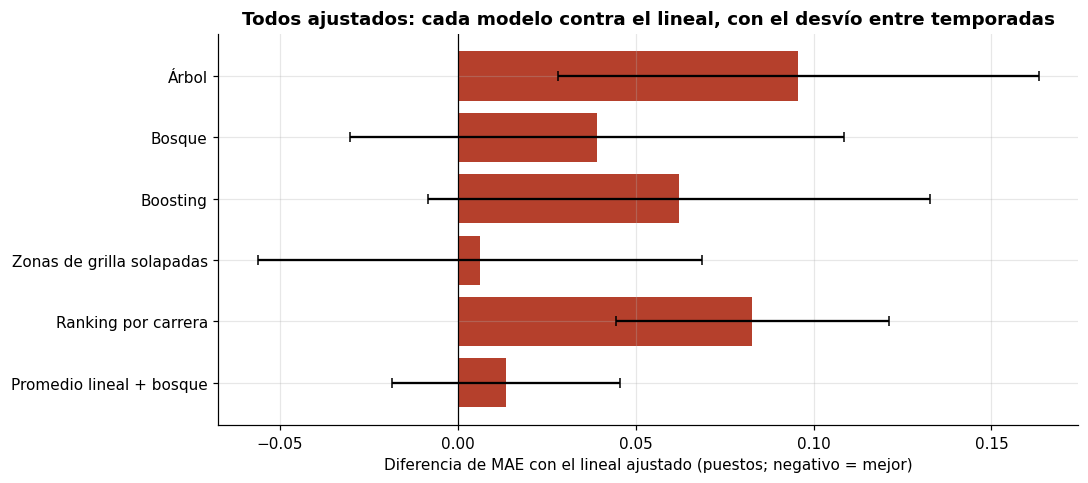

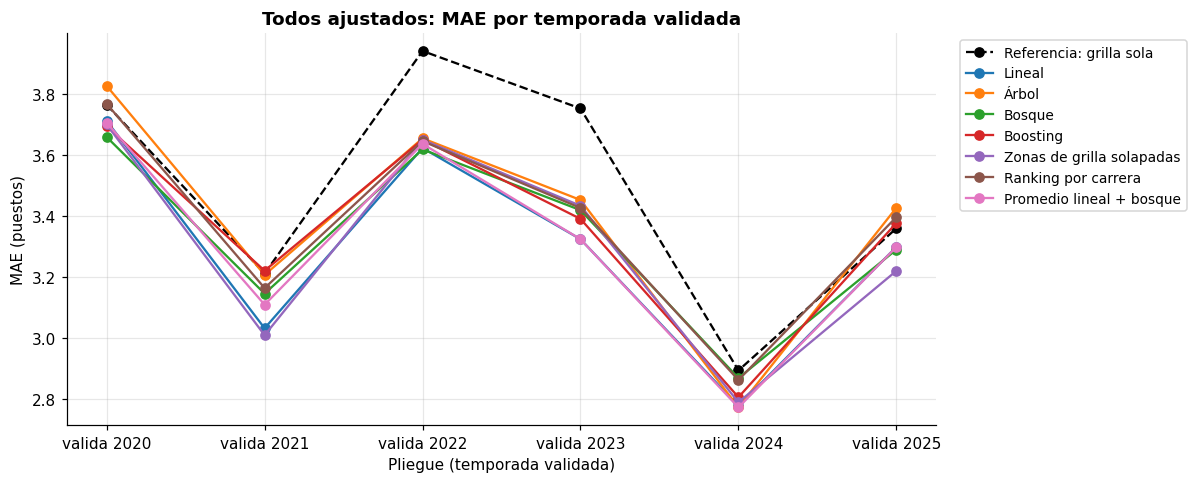

In [ ]:
resultados_aj = {n: validar(CONSTRUCTORES[n]().set_params(**MEJORES.get(n, {}))) for n in MODELOS}
resultados_aj[GRILLA] = resultados_cv[GRILLA]

tabla_aj = tabla_resumen({n: resultados_aj[n] for n in [GRILLA] + MODELOS})
tabla_aj.insert(0, "MAE · media sin ajustar", [resultados_cv[n]["MAE (puestos)"].mean() for n in tabla_aj.index])
mostrar(tabla_aj.sort_values("MAE · media"), "Todos los modelos ajustados (validación cruzada por temporada)",
        decimales=3)

tabla_dif_aj = diferencias_contra(resultados_aj, "Lineal", MODELOS[1:])
mae_lineal = resultados_aj["Lineal"]["MAE (puestos)"].mean()
tabla_dif_aj.insert(1, "Diferencia en % del MAE del lineal", tabla_dif_aj.iloc[:, 0] / mae_lineal * 100)
mostrar(tabla_dif_aj.sort_values(tabla_dif_aj.columns[0]),
        "Cada modelo ajustado contra el lineal ajustado (negativo = mejor que el lineal)", decimales=3)

ELEGIDO = regla(tabla_dif_aj)
MEJORES_PARAMS = MEJORES.get(ELEGIDO, {})
print(f"Modelo elegido: {ELEGIDO} · hiperparámetros: {legible(MEJORES_PARAMS) or 'los de sus modelos base'}")

fig, ax = plt.subplots(figsize=(10, 0.5 * len(tabla_dif_aj) + 1.5))
ax.barh(tabla_dif_aj.index, tabla_dif_aj.iloc[:, 0], xerr=tabla_dif_aj["Diferencia · desvío"], capsize=3,
        color=[AZUL if v < 0 else ROJO for v in tabla_dif_aj.iloc[:, 0]])
ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()
ax.set_xlabel("Diferencia de MAE con el lineal ajustado (puestos; negativo = mejor)")
ax.set_title("Todos ajustados: cada modelo contra el lineal, con el desvío entre temporadas")
plt.tight_layout()
plt.show()

grafico_por_pliegue(resultados_aj, [GRILLA] + MODELOS, "Todos ajustados: MAE por temporada validada")

### El ajuste del elegido: la grilla completa

La tabla con todas las combinaciones del modelo elegido, ordenadas por MAE, y la curva de validación.
Si el elegido es el lineal, la curva recorre la penalización de Ridge: a la izquierda es la regresión
lineal sin penalizar y a la derecha los coeficientes se achican hasta no decir nada.

,alpha,MAE · media,MAE · desvío,MAE · 2025,MAE sin abandonos,RMSE · media,Spearman · media
Puesto en la grilla,,,,,,,
1,"1000,0000","3,2942","0,3521","3,2985","2,1999","4,6919","0,6655"
2,"3000,0000","3,3015","0,3492","3,2810","2,2028","4,6938","0,6652"
3,"300,0000","3,3117","0,3657","3,2941","2,2208","4,7216","0,6612"
4,"10,0000","3,3235","0,3612","3,3290","2,2391","4,7429","0,6581"
5,"100,0000","3,3239","0,3598","3,3203","2,2368","4,7364","0,6590"
6,"1,0000","3,3251","0,3612","3,3333","2,2416","4,7441","0,6579"
7,"0,0100","3,3251","0,3612","3,3333","2,2425","4,7443","0,6579"
8,"10000,0000","3,3353","0,3462","3,3377","2,2364","4,7219","0,6613"
9,"100000,0000","3,3603","0,3363","3,3464","2,2752","4,7559","0,6567"


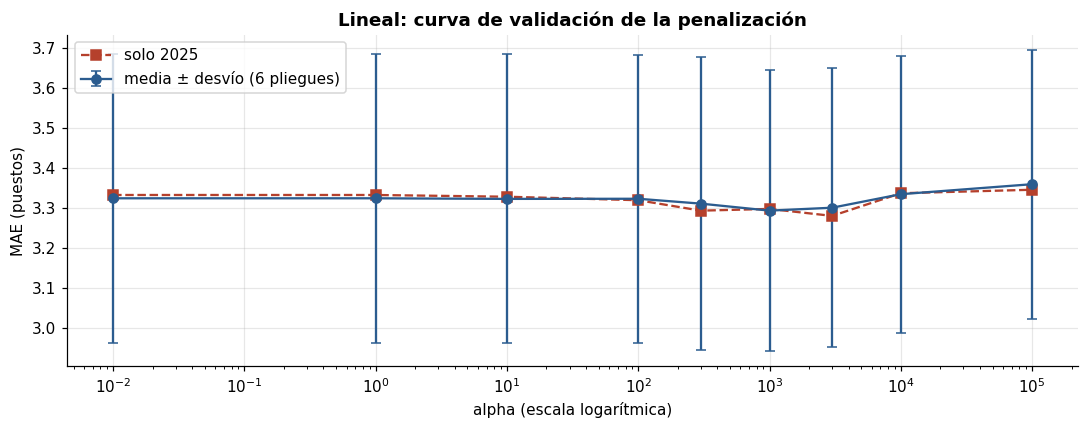

In [ ]:
if ELEGIDO not in TABLAS_GRILLA:
    print(f"{ELEGIDO} no tiene hiperparámetros propios: usa los mejores de sus modelos base.")
else:
    tabla_grilla = TABLAS_GRILLA[ELEGIDO]
    mostrar(tabla_grilla.drop(columns="params"),
            f"{ELEGIDO} (elegido): todas las combinaciones de la grilla ({len(tabla_grilla)})", decimales=4)

    fig, ax = plt.subplots(figsize=(10, 4))
    if "alpha" in tabla_grilla:
        orden = tabla_grilla.sort_values("alpha")
        ax.errorbar(orden["alpha"], orden["MAE · media"], yerr=orden["MAE · desvío"], fmt="o-",
                    capsize=3, color=AZUL, label=f"media ± desvío ({len(PLIEGUES)} pliegues)")
        ax.plot(orden["alpha"], orden[f"MAE · {ANIO_VALIDACION}"], "s--", color=ROJO,
                label=f"solo {ANIO_VALIDACION}")
        ax.set_xscale("log")
        ax.set_xlabel("alpha (escala logarítmica)")
        ax.set_title(f"{ELEGIDO}: curva de validación de la penalización")
        ax.legend()
    else:
        ax.errorbar(tabla_grilla.index, tabla_grilla["MAE · media"], yerr=tabla_grilla["MAE · desvío"],
                    fmt="o", markersize=3, capsize=2, color=AZUL)
        ax.set_xlabel("Combinación (ordenadas de mejor a peor)")
        ax.set_title(f"{ELEGIDO}: MAE de cada combinación de la grilla, con su desvío")
    ax.set_ylabel("MAE (puestos)")
    plt.tight_layout()
    plt.show()

Ajustados todos, ningún modelo le gana al lineal por más que el desvío, así que se queda el lineal:
una regresión Ridge con la penalización que mejor anduvo en la grilla. Con diferencias de centésimas
de puesto preferimos el más simple, que además se puede leer por sus coeficientes. La curva de la
penalización es chata en el medio: entre `alpha` de 100 a 3000 el error casi no cambia, así que el
valor exacto no es una decisión delicada.

No hay clases desparejas que tratar (es una regresión con objetivo plano), así que no hay umbral ni
pesos por clase que ajustar.

### Columnas probadas

Con el modelo y los hiperparámetros elegidos se mide qué pasa al **sacar** cada columna del modelo,
al **agregar** las que el EDA descartó, al quedarse **solo con las que más pesan** y al **pesar la
distancia al líder por fecha**. Cada fila es una validación cruzada completa. La diferencia se calcula
pliegue a pliegue contra el modelo con las 8 columnas: positiva quiere decir que el cambio empeora el
MAE. Para adoptar un cambio se usa la misma regla que con los modelos: tiene que mejorar por más que
el desvío de la diferencia.

,MAE · media,MAE · desvío,MAE · 2025,Diferencia con el elegido · media,Diferencia · desvío,Se adopta,MAE sin abandonos,Acierto podio (%)
Variante,,,,,,,,
Modelo elegido (8 columnas),"3,2942","0,3521","3,2985","0,0000","0,0000",no,"2,1999","66,0024"
sin Q_GridPosition,"3,3995","0,3270","3,4597","0,1053","0,0760",no,"2,2446","64,5604"
sin Q_Best_seconds_DBT_%,"3,3340","0,3417","3,3420","0,0398","0,0177",no,"2,2400","65,7699"
sin DriverPoints_Before_DBT_%,"3,4246","0,3591","3,3290","0,1304","0,1151",no,"2,3642","68,0028"
sin FP_LapTime_min_SOFT_DBT_%,"3,3000","0,3691","3,2985","0,0058","0,0408",no,"2,2046","66,5496"
sin FP_LapTime_min_MED_DBT_%,"3,2996","0,3522","3,3115","0,0054","0,0234",no,"2,1986","67,5096"
sin FP_LapTime_min_HARD_DBT_%,"3,3041","0,3499","3,2941","0,0099","0,0281",no,"2,2153","65,9904"
sin el desgaste (las dos columnas),"3,2987","0,3495","3,3072","0,0045","0,0076",no,"2,2103","66,2550"
sin términos cruzados,"3,3029","0,3568","3,3159","0,0087","0,0087",no,"2,2163","66,2550"


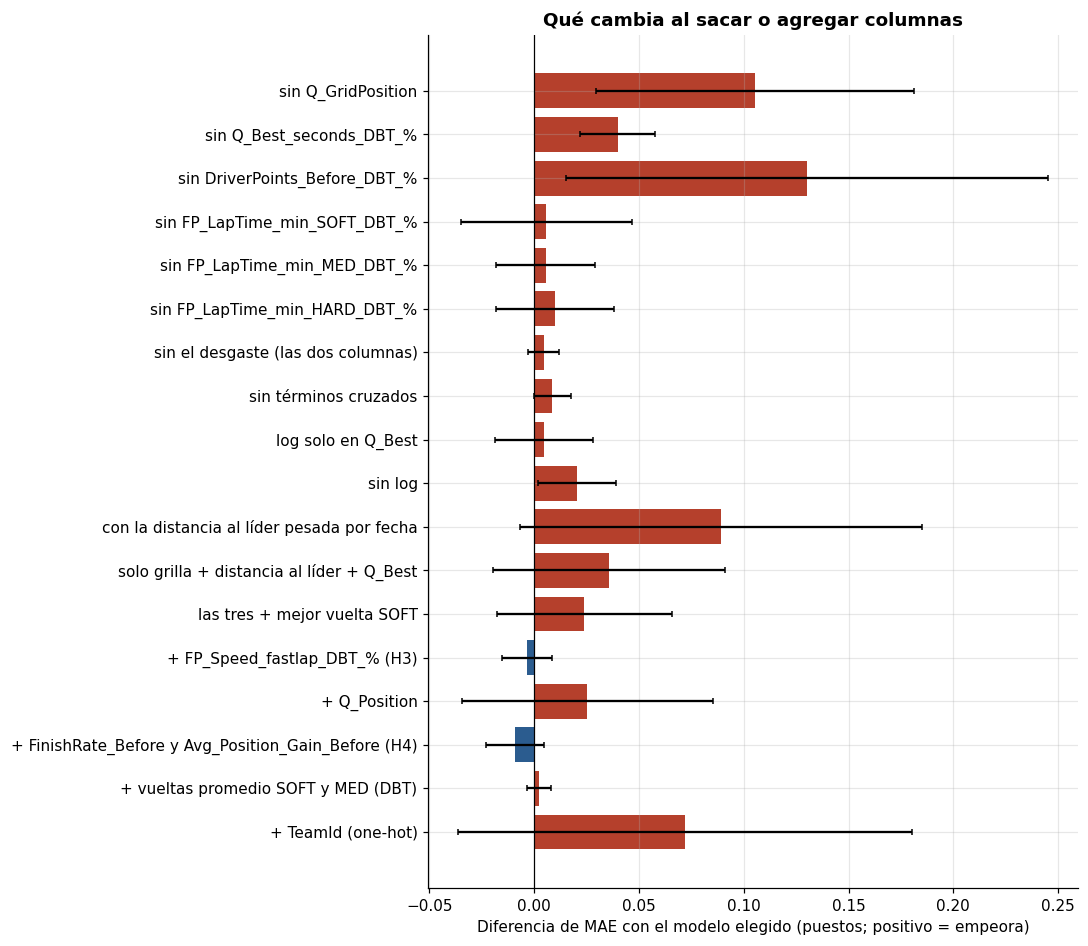

In [ ]:
CONFIG_FINAL = {"columnas": COLUMNAS_BASE, "interacciones": True, "log_cols": TIEMPOS_DBT,
                "categoricas": (), "pesar_distancia": False}
ES_LINEAL = ELEGIDO in ("Lineal", ZONAS)


def modelo_elegido(**cambios):
    return clone(CONSTRUCTORES[ELEGIDO](**{**CONFIG_FINAL, **cambios}).set_params(**MEJORES_PARAMS))


sin = lambda *cs: [c for c in COLUMNAS_BASE if c not in cs]
TRES = ["Q_GridPosition", "DriverPoints_Before_DBT_%", "Q_Best_seconds_DBT_%"]
VARIANTES = {"Modelo elegido (8 columnas)": {}}
for c in COLUMNAS_BASE:
    if c not in DESGASTE:
        VARIANTES[f"sin {c}"] = {"columnas": sin(c)}
VARIANTES["sin el desgaste (las dos columnas)"] = {"columnas": sin(*DESGASTE)}
if ES_LINEAL:
    VARIANTES["sin términos cruzados"] = {"interacciones": False}
    VARIANTES["log solo en Q_Best"] = {"log_cols": ["Q_Best_seconds_DBT_%"]}
    VARIANTES["sin log"] = {"log_cols": []}
VARIANTES["con la distancia al líder pesada por fecha"] = {"pesar_distancia": True}
VARIANTES["solo grilla + distancia al líder + Q_Best"] = {"columnas": TRES}
VARIANTES["las tres + mejor vuelta SOFT"] = {"columnas": TRES + ["FP_LapTime_min_SOFT_DBT_%"]}
VARIANTES["+ FP_Speed_fastlap_DBT_% (H3)"] = {"columnas": COLUMNAS_BASE + ["FP_Speed_fastlap_DBT_%"]}
VARIANTES["+ Q_Position"] = {"columnas": COLUMNAS_BASE + ["Q_Position"]}
VARIANTES["+ FinishRate_Before y Avg_Position_Gain_Before (H4)"] = {
    "columnas": COLUMNAS_BASE + ["FinishRate_Before", "Avg_Position_Gain_Before"]}
VARIANTES["+ vueltas promedio SOFT y MED (DBT)"] = {
    "columnas": COLUMNAS_BASE + ["FP_LapTime_mean_SOFT_DBT_%", "FP_LapTime_mean_MED_DBT_%"]}
VARIANTES["+ TeamId (one-hot)"] = {"columnas": COLUMNAS_BASE + ["TeamId"], "categoricas": ("TeamId",)}

res_variantes = {n: validar(modelo_elegido(**kw)) for n, kw in VARIANTES.items()}
base_var = res_variantes["Modelo elegido (8 columnas)"]["MAE (puestos)"]
filas = []
for n, res in res_variantes.items():
    dif = res["MAE (puestos)"] - base_var
    filas.append({"Variante": n, "MAE · media": res["MAE (puestos)"].mean(),
                  "MAE · desvío": res["MAE (puestos)"].std(),
                  f"MAE · {ANIO_VALIDACION}": res["MAE (puestos)"][PLIEGUE_VAL],
                  "Diferencia con el elegido · media": dif.mean(), "Diferencia · desvío": dif.std(),
                  "Se adopta": "sí" if n != "Modelo elegido (8 columnas)" and -dif.mean() > dif.std() else "no",
                  "MAE sin abandonos": res["MAE sin abandonos"].mean(),
                  "Acierto podio (%)": res["Acierto podio (%)"].mean()})
tabla_variantes = pd.DataFrame(filas).set_index("Variante")
mostrar(tabla_variantes, "Con y sin cada columna (validación cruzada por temporada)", decimales=4)

dif_plot = tabla_variantes.drop(index="Modelo elegido (8 columnas)")
fig, ax = plt.subplots(figsize=(10, 0.4 * len(dif_plot) + 1.5))
ax.barh(dif_plot.index, dif_plot["Diferencia con el elegido · media"],
        xerr=dif_plot["Diferencia · desvío"], capsize=2,
        color=[ROJO if v > 0 else AZUL for v in dif_plot["Diferencia con el elegido · media"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()
ax.set_xlabel("Diferencia de MAE con el modelo elegido (puestos; positivo = empeora)")
ax.set_title("Qué cambia al sacar o agregar columnas")
plt.tight_layout()
plt.show()

### Lo que probamos y no sirvió

Ningún cambio de columnas mejora por más que el desvío, así que el modelo se queda con las 8 columnas
del EDA. Pero la tabla también dice qué decisiones del EDA no se sostienen con los números:

- **El desgaste no aporta.** Sacar las dos columnas cambia el MAE en milésimas. H7 ya decía que solo
  no predice; la idea era que sirviera combinado con la mejor vuelta, y los **términos cruzados**
  tampoco mueven el número. Lo que mostró H6 (el desgaste cambia el peso de la mejor vuelta) no se
  traduce en un modelo mejor.
- **MED y HARD aportan muy poco:** sacarlos sube el MAE menos que el desvío.
- **Pesar la distancia al líder por fecha empeora:** la idea era que en las primeras fechas la
  distancia dice poco, pero al achicarla se pierde casi toda la información de la columna.
- **`TeamId` empeora**, sobre todo en 2025: la fuerza de un equipo no se traslada de una temporada a
  otra (Sección 4).
- **Las columnas descartadas en el EDA** (telemetría, contexto de la fecha, vueltas promedio,
  `Q_Position`) no mejoran por más que el desvío.

Lo que sí pesa: sin la grilla, sin Q_Best o sin la distancia al líder el error sube. El desgaste y
los términos cruzados se quedan porque sacarlos tampoco mejora por más que el desvío, y cambiar las
columnas mirando esta misma tabla sería elegirlas con los mismos pliegues con que se miden.

### Todas las combinaciones de columnas

En lugar de probar combinaciones a mano, se prueban **todas**: las 8 columnas forman 7 bloques (el
desgaste va junto) y hay 127 subconjuntos posibles. Cada uno se mide con el modelo elegido, con sus
hiperparámetros, y los mismos pliegues.

Elegir el mejor de 127 subconjuntos con los mismos pliegues es optimista: alguno va a salir bien por
azar. Por eso esta tabla se lee como evidencia de **qué bloques aparecen siempre en los mejores**, no
como la forma de elegir columnas. La grilla y Q_Best dicen casi lo mismo (la grilla es el orden de la
clasificación con las penalizaciones aplicadas): si aparecen subconjuntos buenos sin la grilla, es
porque Q_Best la reemplaza.

,Bloques,Cantidad,MAE · media,MAE · desvío
1,Grilla + Distancia al líder + Q_Best + SOFT + MED + HARD + Desgaste,7,"3,2942","0,3521"
2,Grilla + Distancia al líder + Q_Best + SOFT + MED + HARD,6,"3,2987","0,3495"
3,Grilla + Distancia al líder + Q_Best + SOFT + HARD + Desgaste,6,"3,2996","0,3522"
4,Grilla + Distancia al líder + Q_Best + MED + HARD + Desgaste,6,"3,3000","0,3691"
5,Grilla + Distancia al líder + Q_Best + SOFT + HARD,5,"3,3019","0,3516"
6,Grilla + Distancia al líder + Q_Best + HARD + Desgaste,5,"3,3033","0,3787"
7,Grilla + Distancia al líder + Q_Best + SOFT + MED + Desgaste,6,"3,3041","0,3499"
8,Grilla + Distancia al líder + Q_Best + MED + HARD,5,"3,3046","0,3707"
9,Grilla + Distancia al líder + Q_Best + MED + Desgaste,5,"3,3072","0,3622"
10,Grilla + Distancia al líder + Q_Best + SOFT + MED,5,"3,3113","0,3450"


,% de los 20 mejores que lo incluyen
Grilla,100
Distancia al líder,100
Q_Best,75
HARD,65
SOFT,55
MED,45
Desgaste,45


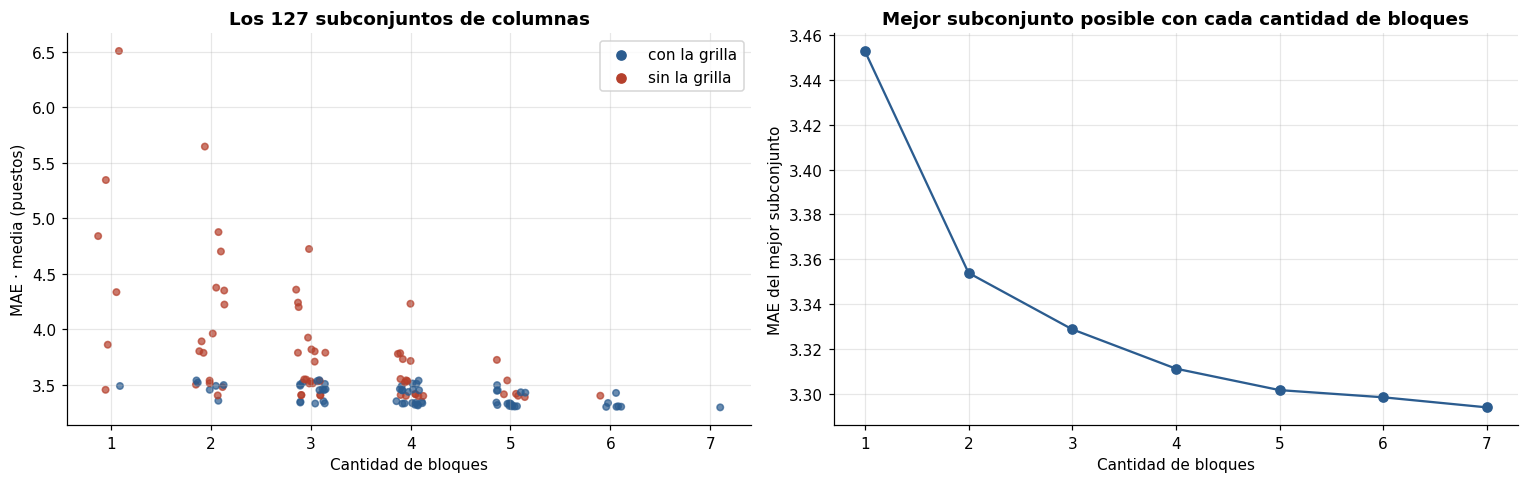

,Valor
Spearman grilla ~ Q_Best,"0,820"
"Spearman grilla ~ Q_Best (por carrera, media)","0,937"


In [ ]:
BLOQUES = {
    "Grilla": ["Q_GridPosition"],
    "Distancia al líder": ["DriverPoints_Before_DBT_%"],
    "Q_Best": ["Q_Best_seconds_DBT_%"],
    "SOFT": ["FP_LapTime_min_SOFT_DBT_%"],
    "MED": ["FP_LapTime_min_MED_DBT_%"],
    "HARD": ["FP_LapTime_min_HARD_DBT_%"],
    "Desgaste": DESGASTE,
}
filas = []
for k in range(1, len(BLOQUES) + 1):
    for combo in combinations(BLOQUES, k):
        cols = [c for b in combo for c in BLOQUES[b]]
        res = validar(modelo_elegido(columnas=cols))
        filas.append({"Bloques": " + ".join(combo), "Cantidad": k, **{b: b in combo for b in BLOQUES},
                      "MAE · media": res["MAE (puestos)"].mean(), "MAE · desvío": res["MAE (puestos)"].std()})
subconjuntos = pd.DataFrame(filas).sort_values("MAE · media").reset_index(drop=True)
subconjuntos.index = subconjuntos.index + 1
puesto_completo = subconjuntos.index[subconjuntos["Cantidad"] == len(BLOQUES)][0]

mostrar(subconjuntos.head(15)[["Bloques", "Cantidad", "MAE · media", "MAE · desvío"]],
        f"Los 15 mejores subconjuntos de {len(subconjuntos)} (el modelo con los 7 bloques queda {puesto_completo}.º)",
        decimales=4)

presencia = (subconjuntos.head(20)[list(BLOQUES)].mean() * 100).sort_values(ascending=False)
mostrar(presencia.to_frame("% de los 20 mejores que lo incluyen"), "Qué bloques aparecen en los 20 mejores subconjuntos",
        decimales=0, gradiente=["% de los 20 mejores que lo incluyen"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rng = np.random.default_rng(SEMILLA)
jit = rng.uniform(-0.15, 0.15, len(subconjuntos))
axes[0].scatter(subconjuntos["Cantidad"] + jit, subconjuntos["MAE · media"],
                c=np.where(subconjuntos["Grilla"], AZUL, ROJO), s=18, alpha=0.7)
axes[0].scatter([], [], c=AZUL, label="con la grilla")
axes[0].scatter([], [], c=ROJO, label="sin la grilla")
axes[0].set_xlabel("Cantidad de bloques")
axes[0].set_ylabel("MAE · media (puestos)")
axes[0].set_title(f"Los {len(subconjuntos)} subconjuntos de columnas")
axes[0].legend()
mejor_k = subconjuntos.groupby("Cantidad")["MAE · media"].min()
axes[1].plot(mejor_k.index, mejor_k.values, marker="o", color=AZUL)
axes[1].set_xlabel("Cantidad de bloques")
axes[1].set_ylabel("MAE del mejor subconjunto")
axes[1].set_title("Mejor subconjunto posible con cada cantidad de bloques")
plt.tight_layout()
plt.show()

spearman_carrera = np.mean([g["Q_GridPosition"].corr(g["Q_Best_seconds_DBT_%"], method="spearman")
                            for _, g in tr.groupby("Carrera")])
mostrar(pd.Series({
    "Spearman grilla ~ Q_Best": tr["Q_GridPosition"].corr(tr["Q_Best_seconds_DBT_%"], method="spearman"),
    "Spearman grilla ~ Q_Best (por carrera, media)": spearman_carrera,
}).to_frame("Valor"), "Cuánto se parecen la grilla y Q_Best (entrenamiento 2018–2025)", decimales=3)

La curva del mejor subconjunto se aplana después de tres o cuatro bloques: grilla (o Q_Best),
distancia al líder y una mejor vuelta de prácticas explican casi todo lo que el modelo sabe. El modelo
completo queda entre los mejores sin ser el primero, y la diferencia con el primero está dentro del
desvío, así que no hay motivo para cambiar las columnas decididas en el EDA.

## Sección 7: El modelo final sobre el test 2026

Todo lo que se eligió (modelo, hiperparámetros, columnas) se eligió con la validación cruzada sobre
2018–2025. El modelo final se entrena con todo ese período y se mide **una sola vez** sobre 2026,
**solo el modelo elegido**. El piso y la referencia de la grilla se miden sobre el mismo test, para
que los números sean comparables; no son candidatos.

El modelo final se entrena solo con las columnas que necesita (`ENTRADA_FINAL`), que son las que va
a tener que mandarle la aplicación.

In [ ]:
final = modelo_elegido().fit(tr[ENTRADA_FINAL], y_tr)
pred_te = final.predict(te[ENTRADA_FINAL])

piso_te = armar_pipeline(DummyRegressor(strategy="mean")).fit(X_tr, y_tr).predict(X_te)
grilla_te = armar_pipeline(ReglaGrilla(), columnas=["Q_GridPosition"], lineal=False).fit(X_tr, y_tr).predict(X_te)
FINAL = f"Modelo final ({ELEGIDO})"

tabla_test = pd.DataFrame([
    {"Modelo": PISO, **medir(piso_te, te)},
    {"Modelo": GRILLA, **medir(grilla_te, te)},
    {"Modelo": FINAL, **medir(pred_te, te)},
]).set_index("Modelo")[METRICAS + METRICAS_ABANDONO]
mostrar(tabla_test, f"Test {ANIO_TEST} ({te.Carrera.nunique()} carreras, {len(te)} filas)", decimales=3)

cv_elegido = res_variantes["Modelo elegido (8 columnas)"]
comparacion = pd.DataFrame({
    f"CV · media ({PRIMER_ANIO_VALIDACION}–{ANIO_VALIDACION})": cv_elegido[METRICAS + METRICAS_ABANDONO].mean(),
    f"Validación {ANIO_VALIDACION}": cv_elegido.loc[PLIEGUE_VAL, METRICAS + METRICAS_ABANDONO],
    f"Test {ANIO_TEST}": tabla_test.loc[FINAL],
})
mostrar(comparacion, "Modelo final: validación cruzada, validación 2025 y test 2026", decimales=3)

,MAE (puestos),RMSE (puestos),Mediana del error absoluto,Acierto ±2 puestos (%),Spearman por carrera,Acierto zona de puntos (%),Acierto podio (%),Acierto ganador (%),MAE sin abandonos,RMSE sin abandonos
Modelo,,,,,,,,,,
Piso: Dummy (media),"5,500","6,344","5,500","18,182",—,—,—,—,"4,381","5,084"
Referencia: grilla sola,"3,497","5,379","2,000","55,594","0,641","73,846","58,974","69,231","1,956","2,990"
Modelo final (Lineal),"3,490","5,181","2,000","55,245","0,667","76,154","61,538","46,154","1,726","2,489"


,CV · media (2020–2025),Validación 2025,Test 2026
MAE (puestos),"3,294","3,298","3,490"
RMSE (puestos),"4,692","4,744","5,181"
Mediana del error absoluto,"2,333","2,000","2,000"
Acierto ±2 puestos (%),"53,314","54,031","55,245"
Spearman por carrera,"0,666","0,660","0,667"
Acierto zona de puntos (%),"78,180","76,522","76,154"
Acierto podio (%),"66,002","68,116","61,538"
Acierto ganador (%),"58,449","56,522","46,154"
MAE sin abandonos,"2,200","2,333","1,726"
RMSE sin abandonos,"3,116","3,345","2,489"


### Con abandonos y sin abandonos

El MAE con todos los pilotos es el número que se informa, porque antes de la carrera no se sabe quién
va a abandonar. Pero mezcla dos errores distintos: **el orden mal leído** entre los que corrieron
toda la carrera, y **los abandonos**, que mandan al fondo a un piloto que el modelo (con razón, según
lo que se sabía antes de largar) había puesto adelante. Separarlos dice cuánto del error es del
modelo y cuánto es de algo que ninguna columna previa a la carrera puede ver.

,MAE con abandonos,MAE sin abandonos,RMSE con abandonos,RMSE sin abandonos
Modelo,,,,
Piso: Dummy (media),"5,500","4,381","6,344","5,084"
Referencia: grilla sola,"3,497","1,956","5,379","2,990"
Modelo final (Lineal),"3,490","1,726","5,181","2,489"


,Con abandonos,Sin abandonos,Sin / con
Validación cruzada,"0,193","0,260","1,347"
Test 2026,"0,007","0,230","32,903"


,Puestos de MAE
Mejora sobre el piso,"2,010"
Mejora sobre la grilla sola,"0,007"
"Mejora sobre la grilla sola, sin abandonos","0,230"


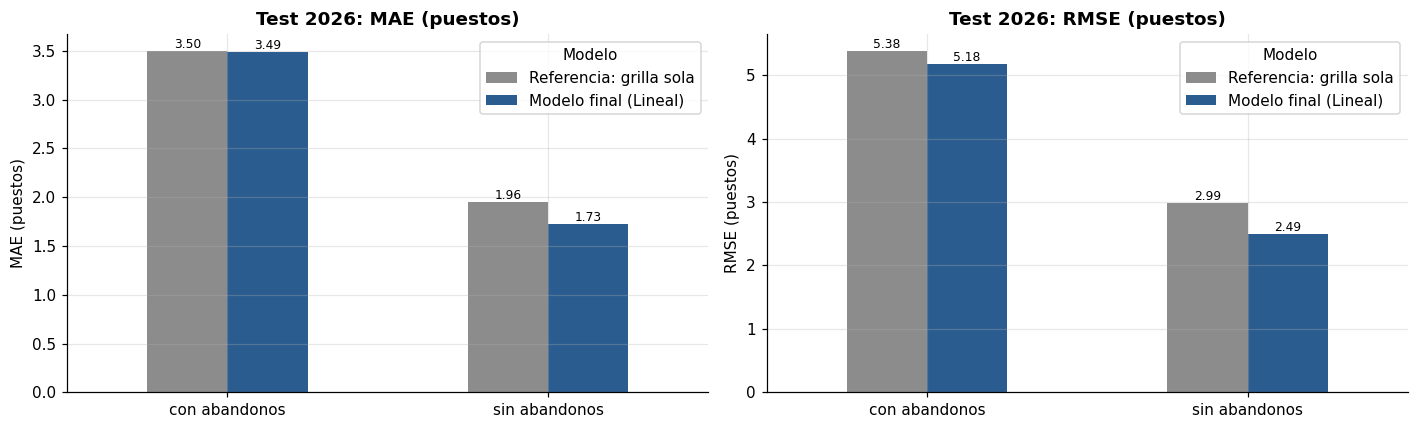

In [ ]:
def ventaja(tabla, col):
    return tabla.loc[GRILLA, col] - tabla.loc[FINAL, col]


con_sin_test = pd.DataFrame({
    "MAE con abandonos": tabla_test["MAE (puestos)"],
    "MAE sin abandonos": tabla_test["MAE sin abandonos"],
    "RMSE con abandonos": tabla_test["RMSE (puestos)"],
    "RMSE sin abandonos": tabla_test["RMSE sin abandonos"],
})
mostrar(con_sin_test, f"Test {ANIO_TEST}: el error con todos los pilotos y solo con los que terminaron", decimales=3)

cv_grilla = resultados_cv[GRILLA]
ventajas = pd.DataFrame({
    "Con abandonos": {
        "Validación cruzada": cv_grilla["MAE (puestos)"].mean() - cv_elegido["MAE (puestos)"].mean(),
        f"Test {ANIO_TEST}": ventaja(con_sin_test, "MAE con abandonos")},
    "Sin abandonos": {
        "Validación cruzada": cv_grilla["MAE sin abandonos"].mean() - cv_elegido["MAE sin abandonos"].mean(),
        f"Test {ANIO_TEST}": ventaja(con_sin_test, "MAE sin abandonos")},
})
ventajas["Sin / con"] = ventajas["Sin abandonos"] / ventajas["Con abandonos"]
mostrar(ventajas, "Cuántos puestos de MAE le gana el modelo a la grilla, con y sin abandonos", decimales=3)

mostrar(pd.DataFrame({"Puestos de MAE": {
    "Mejora sobre el piso": tabla_test.loc[PISO, "MAE (puestos)"] - tabla_test.loc[FINAL, "MAE (puestos)"],
    "Mejora sobre la grilla sola": tabla_test.loc[GRILLA, "MAE (puestos)"] - tabla_test.loc[FINAL, "MAE (puestos)"],
    "Mejora sobre la grilla sola, sin abandonos": ventaja(con_sin_test, "MAE sin abandonos"),
}}), "Cuánto le gana el modelo final a cada referencia en el test", decimales=3)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (titulo, cols) in zip(axes, [("MAE (puestos)", ["MAE con abandonos", "MAE sin abandonos"]),
                                     ("RMSE (puestos)", ["RMSE con abandonos", "RMSE sin abandonos"])]):
    t = con_sin_test.loc[[GRILLA, FINAL], cols]
    t.columns = ["con abandonos", "sin abandonos"]
    t.T.plot.bar(ax=ax, rot=0, color=[GRIS, AZUL])
    ax.set_title(f"Test {ANIO_TEST}: {titulo}")
    ax.set_ylabel(titulo)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()

Con todos los pilotos, el modelo y la grilla quedan casi empatados en el test. **Sin los abandonos,
el modelo le gana a la grilla con claridad**, y el RMSE baja mucho más que el MAE: los errores grandes
eran abandonos. Lo que el modelo agrega sobre la grilla (la distancia al líder y el ritmo de
prácticas) sirve para ordenar a los que terminan la carrera, y esa mejora queda tapada por los
abandonos, que le pegan igual al modelo y a la grilla y que ninguna de las dos puede anticipar.

La lectura es que el modelo es mejor que la grilla en lo que se le puede pedir, y que el límite del
error no está en el modelo sino en la información: con una columna que anticipara los abandonos el
número con todos los pilotos se acercaría al sin abandonos. La Sección 8 mide si con las columnas que
hay se pueden anticipar.

,Con abandonos,Sin abandonos
Carreras en que el modelo erra menos que la grilla,5,8
Carreras en que erra más,7,4
Carreras empatadas,1,1


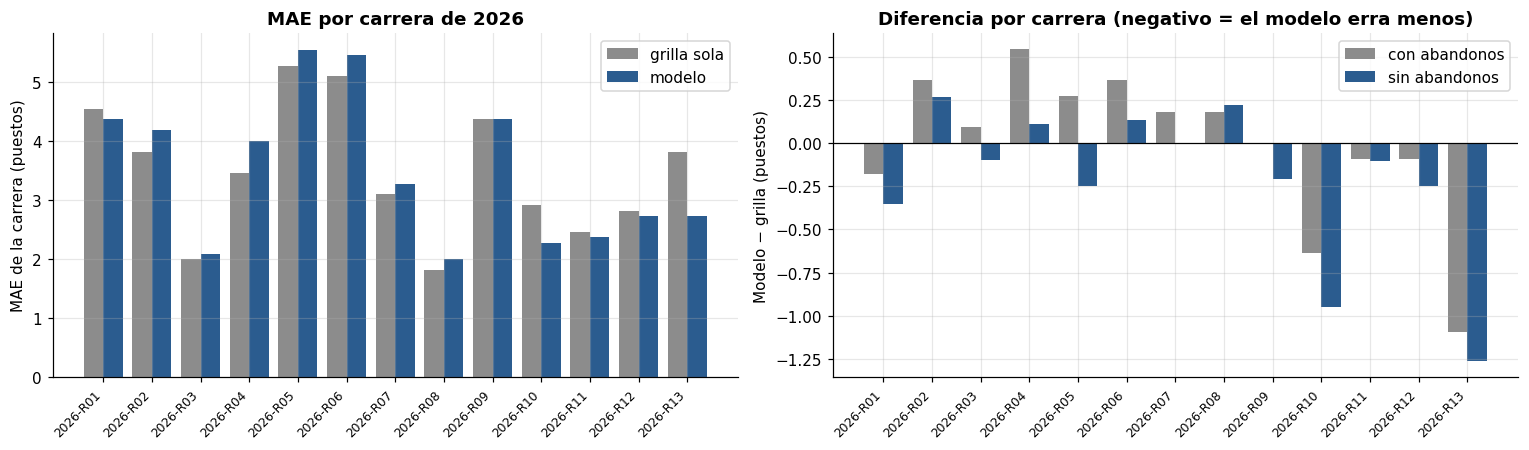

In [ ]:
def error_abs_sin_abandonos(pred, datos):
    # Error absoluto de cada piloto que terminó, con puestos re-numerados 1..k en su carrera.
    car = datos["Carrera"]
    p = puesto_en_carrera(pred, car)
    r = datos["Puesto"].groupby(car).rank(method="average")
    t = datos["Terminó"].fillna(False).astype(bool)
    pf = p[t].groupby(car[t]).rank(method="average")
    rf = r[t].groupby(car[t]).rank(method="average")
    return (pf - rf).abs()


por_carrera_te = pd.DataFrame({
    "Modelo": (puesto_en_carrera(pred_te, te["Carrera"]) - te["Puesto"]).abs(),
    "Grilla": (puesto_en_carrera(grilla_te, te["Carrera"]) - te["Puesto"]).abs(),
}).groupby(te["Carrera"]).mean()
por_carrera_te["Diferencia"] = por_carrera_te["Modelo"] - por_carrera_te["Grilla"]
sin_ab = pd.DataFrame({"Modelo": error_abs_sin_abandonos(pred_te, te),
                       "Grilla": error_abs_sin_abandonos(grilla_te, te)}).groupby(te["Carrera"]).mean()
por_carrera_te["Diferencia sin abandonos"] = sin_ab["Modelo"] - sin_ab["Grilla"]

mostrar(pd.DataFrame({
    "Con abandonos": {"Carreras en que el modelo erra menos que la grilla": int((por_carrera_te["Diferencia"] < 0).sum()),
                      "Carreras en que erra más": int((por_carrera_te["Diferencia"] > 0).sum()),
                      "Carreras empatadas": int((por_carrera_te["Diferencia"] == 0).sum())},
    "Sin abandonos": {"Carreras en que el modelo erra menos que la grilla": int((por_carrera_te["Diferencia sin abandonos"] < 0).sum()),
                      "Carreras en que erra más": int((por_carrera_te["Diferencia sin abandonos"] > 0).sum()),
                      "Carreras empatadas": int((por_carrera_te["Diferencia sin abandonos"] == 0).sum())},
}), f"Test: modelo contra grilla, carrera por carrera ({len(por_carrera_te)} carreras)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(por_carrera_te))
axes[0].bar(x - 0.2, por_carrera_te["Grilla"], width=0.4, color=GRIS, label="grilla sola")
axes[0].bar(x + 0.2, por_carrera_te["Modelo"], width=0.4, color=AZUL, label="modelo")
axes[0].set_xticks(x, por_carrera_te.index, rotation=45, ha="right", fontsize=8)
axes[0].set_ylabel("MAE de la carrera (puestos)")
axes[0].set_title(f"MAE por carrera de {ANIO_TEST}")
axes[0].legend()
axes[1].bar(x - 0.2, por_carrera_te["Diferencia"], width=0.4, color=GRIS, label="con abandonos")
axes[1].bar(x + 0.2, por_carrera_te["Diferencia sin abandonos"], width=0.4, color=AZUL, label="sin abandonos")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xticks(x, por_carrera_te.index, rotation=45, ha="right", fontsize=8)
axes[1].set_ylabel("Modelo − grilla (puestos)")
axes[1].set_title("Diferencia por carrera (negativo = el modelo erra menos)")
axes[1].legend()
plt.tight_layout()
plt.show()

## Sección 8: Dónde se equivoca

Con el modelo final sobre el test: el puesto real contra el predicho, el error según el puesto real y
según la grilla, una tabla de franjas real × predicho normalizada por fila (de los que terminaron en
una franja, dónde los puso el modelo) y por columna (de los que el modelo puso en una franja, dónde
terminaron), el peso de los abandonos, el error por equipo y los casos puntuales.

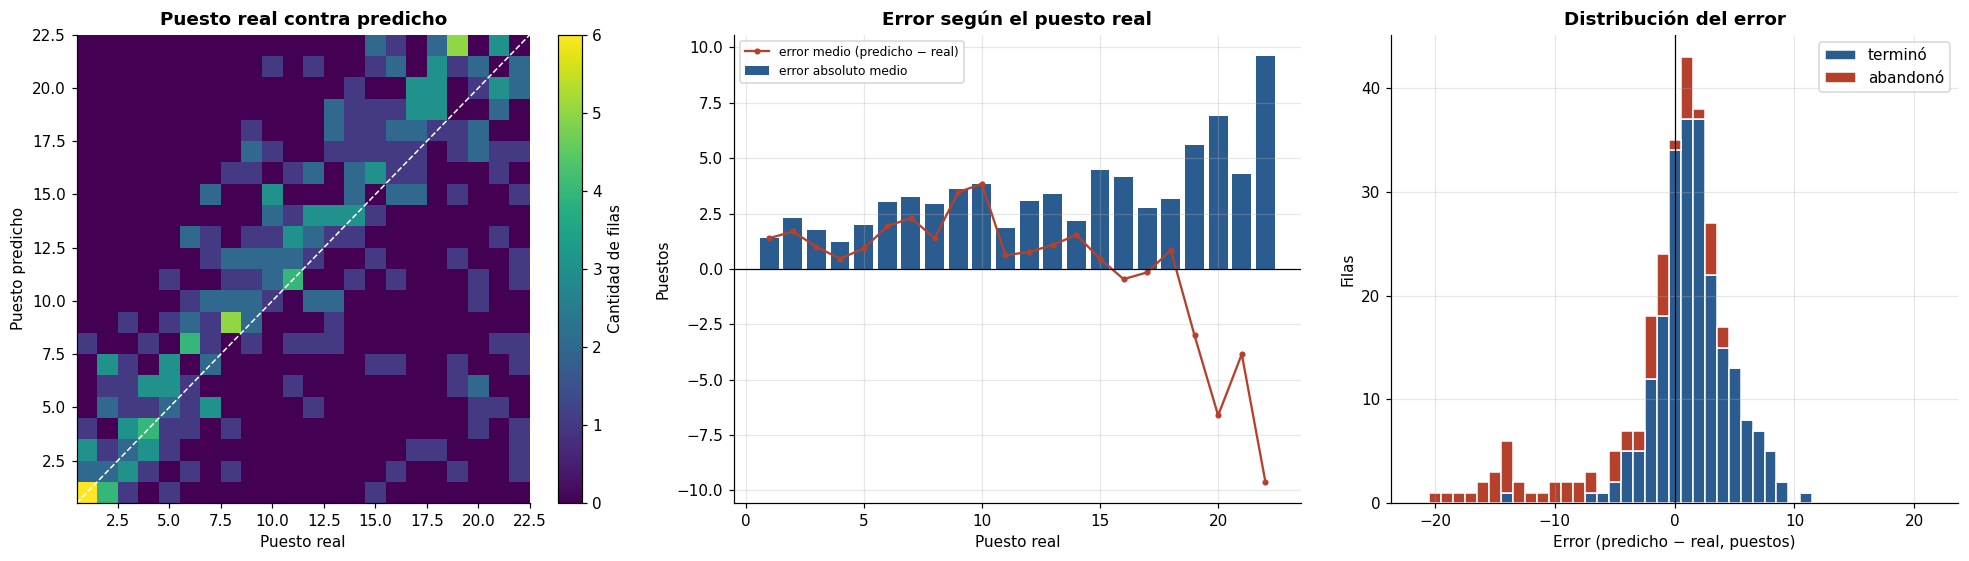

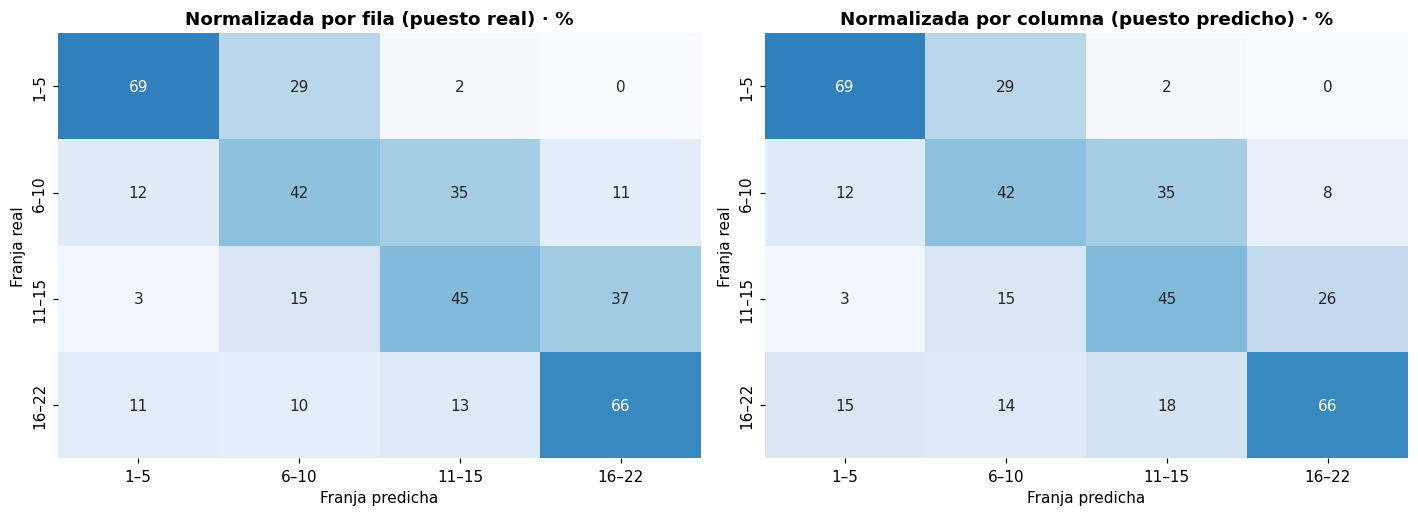

In [ ]:
FRANJAS = [0, 5, 10, 15, 22]
NOMBRES_FRANJAS = ["1–5", "6–10", "11–15", "16–22"]

errores = te[["Carrera", "RoundNumber", "DriverId", "TeamId", "Q_GridPosition", "Puesto", "Terminó"]].copy()
errores["Puesto predicho"] = puesto_en_carrera(pred_te, te["Carrera"])
errores["Error"] = errores["Puesto predicho"] - errores["Puesto"]
errores["Franja real"] = pd.cut(errores["Puesto"], FRANJAS, labels=NOMBRES_FRANJAS)
errores["Franja predicha"] = pd.cut(errores["Puesto predicho"], FRANJAS, labels=NOMBRES_FRANJAS)
errores["Franja de grilla"] = pd.cut(errores["Q_GridPosition"].fillna(21), FRANJAS, labels=NOMBRES_FRANJAS)
err_abs = errores["Error"].abs()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
h = axes[0].hist2d(errores["Puesto"], errores["Puesto predicho"],
                   bins=[np.arange(0.5, 23.5, 1), np.arange(0.5, 23.5, 1)], cmap="viridis")
axes[0].plot([0.5, 22.5], [0.5, 22.5], "--", color="white", linewidth=1)
axes[0].set_xlabel("Puesto real")
axes[0].set_ylabel("Puesto predicho")
axes[0].set_title("Puesto real contra predicho")
axes[0].grid(False)
fig.colorbar(h[3], ax=axes[0], label="Cantidad de filas")

por_puesto = errores.groupby("Puesto")["Error"].agg(lambda e: e.abs().mean())
sesgo = errores.groupby("Puesto")["Error"].mean()
axes[1].bar(por_puesto.index, por_puesto.values, color=AZUL, label="error absoluto medio")
axes[1].plot(sesgo.index, sesgo.values, color=ROJO, marker="o", markersize=3, label="error medio (predicho − real)")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Puesto real")
axes[1].set_ylabel("Puestos")
axes[1].set_title("Error según el puesto real")
axes[1].legend(fontsize=8)

termino_te = errores["Terminó"].fillna(True).astype(bool)
bins = np.arange(-21.5, 22.5, 1)
axes[2].hist([errores.loc[termino_te, "Error"], errores.loc[~termino_te, "Error"]], bins=bins,
             stacked=True, color=[AZUL, ROJO], edgecolor="white", label=["terminó", "abandonó"])
axes[2].axvline(0, color="black", linewidth=0.8)
axes[2].set_xlabel("Error (predicho − real, puestos)")
axes[2].set_ylabel("Filas")
axes[2].set_title("Distribución del error")
axes[2].legend()
plt.tight_layout()
plt.show()

por_tramo = pd.concat({
    "Según el puesto real": errores.groupby("Franja real", observed=True)["Error"].agg(
        n="size", MAE=lambda e: e.abs().mean(), sesgo="mean"),
    "Según la grilla": errores.groupby("Franja de grilla", observed=True)["Error"].agg(
        n="size", MAE=lambda e: e.abs().mean(), sesgo="mean"),
})
por_tramo.index.names = ["Corte", "Franja"]
mostrar(por_tramo, "Error por tramo (sesgo = predicho − real; positivo = lo pone más atrás)", decimales=2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, norm, titulo in [(axes[0], "index", "Normalizada por fila (puesto real)"),
                         (axes[1], "columns", "Normalizada por columna (puesto predicho)")]:
    t = pd.crosstab(errores["Franja real"], errores["Franja predicha"], normalize=norm) * 100
    sns.heatmap(t, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax, vmin=0, vmax=100)
    ax.set_xlabel("Franja predicha")
    ax.set_ylabel("Franja real")
    ax.set_title(titulo + " · %")
    ax.grid(False)
plt.tight_layout()
plt.show()

El error crece hacia el fondo de la tabla: los que terminan 16.º o peor tienen el MAE más alto y un
sesgo negativo (el modelo los ponía más adelante). Mirado por grilla, el error más grande está en los
que largan adelante. Las dos cosas son la misma: un auto que larga entre los primeros y termina en el
fondo casi siempre es un abandono o un incidente, y el modelo, como la grilla, lo pone donde largó.
La tabla de franjas confirma que la confusión fuerte es esa (real 16–22, predicho 1–5 o 6–10); entre
franjas vecinas el modelo se equivoca poco.

In [ ]:
abandono = ~termino_te
caida = (errores["Q_GridPosition"] <= 10) & (errores["Puesto"] >= 18)
mostrar(pd.DataFrame({
    "Abandonos (no terminaron)": {
        "Filas": int(abandono.sum()), "% de las filas": abandono.mean() * 100,
        "% del error absoluto total que explican": err_abs[abandono].sum() / err_abs.sum() * 100,
        "MAE de esas filas": err_abs[abandono].mean()},
    "Largaron 1–10 y terminaron 18.º o peor": {
        "Filas": int(caida.sum()), "% de las filas": caida.mean() * 100,
        "% del error absoluto total que explican": err_abs[caida].sum() / err_abs.sum() * 100,
        "MAE de esas filas": err_abs[caida].mean()},
    "Resto de las filas": {
        "Filas": int((~abandono).sum()), "% de las filas": (~abandono).mean() * 100,
        "% del error absoluto total que explican": err_abs[~abandono].sum() / err_abs.sum() * 100,
        "MAE de esas filas": err_abs[~abandono].mean()},
}), f"Peso de los abandonos en el error del test {ANIO_TEST}", decimales=1)

,Abandonos (no terminaron),Largaron 1–10 y terminaron 18.º o peor,Resto de las filas
Filas,"60,0","17,0","226,0"
% de las filas,"21,0","5,9","79,0"
% del error absoluto total que explican,"41,7","24,7","58,3"
MAE de esas filas,"6,9","14,5","2,6"


### ¿Se pueden anticipar los abandonos?

Un enfoque en dos pasos (primero predecir quién abandona y después ordenar al resto) solo sirve si el
primer paso funciona. Se prueba lo mínimo: una regresión logística con las mismas 8 columnas y el
mismo pipeline intenta anticipar quién no termina, con `class_weight="balanced"` porque los abandonos
son pocos. Se mide con AUC en los mismos pliegues de la validación cruzada (no se toca el test), para
todos los pilotos y solo para los que largan entre los 10 primeros, que son los abandonos que más
error agregan. **Un AUC de 0,5 es adivinar al azar.**

,% que abandona,AUC · todos,AUC · largan 1–10
Pliegue,,,
valida 2020,"16,765","0,587","0,618"
valida 2021,"13,182","0,540","0,413"
valida 2022,"16,818","0,533","0,529"
valida 2023,"11,905","0,563","0,586"
valida 2024,"10,021","0,648","0,677"
valida 2025,"12,200","0,572","0,575"


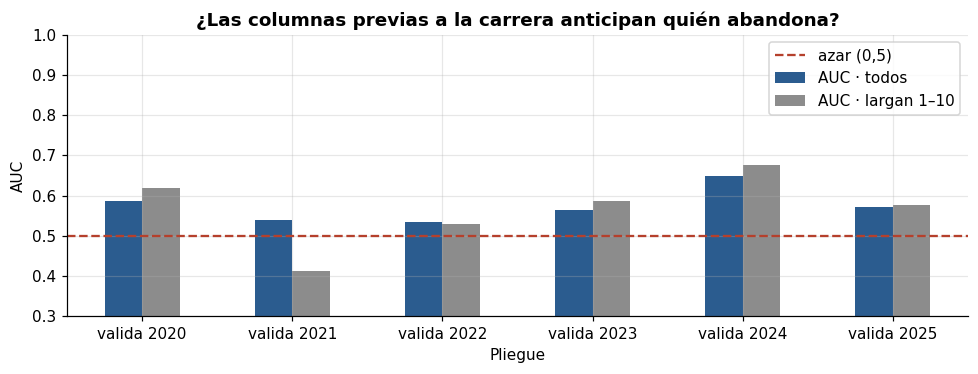

In [ ]:
if df["Terminó"].notna().any():
    filas = []
    for nombre, a, b in PLIEGUES:
        ent, val = tr.iloc[a], tr.iloc[b]
        y_ent = (~ent["Terminó"].fillna(True).astype(bool)).astype(int)
        y_val = (~val["Terminó"].fillna(True).astype(bool)).astype(int)
        clf = armar_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced")).fit(ent[ENTRADA], y_ent)
        prob = pd.Series(clf.predict_proba(val[ENTRADA])[:, 1], index=val.index)
        punta = val["Q_GridPosition"] <= 10
        filas.append({"Pliegue": nombre, "% que abandona": y_val.mean() * 100,
                      "AUC · todos": roc_auc_score(y_val, prob),
                      "AUC · largan 1–10": roc_auc_score(y_val[punta], prob[punta]) if y_val[punta].nunique() > 1 else np.nan})
    tabla_abandonos = pd.DataFrame(filas).set_index("Pliegue")
    mostrar(tabla_abandonos, f"Anticipar abandonos con las columnas previas a la carrera "
            f"(AUC medio {tabla_abandonos['AUC · todos'].mean():.3f})".replace(".", ","), decimales=3)

    fig, ax = plt.subplots(figsize=(9, 3.5))
    tabla_abandonos[["AUC · todos", "AUC · largan 1–10"]].plot.bar(ax=ax, rot=0, color=[AZUL, GRIS])
    ax.axhline(0.5, color=ROJO, linestyle="--", label="azar (0,5)")
    ax.set_ylim(0.3, 1)
    ax.set_ylabel("AUC")
    ax.set_title("¿Las columnas previas a la carrera anticipan quién abandona?")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Sin RACE_Finished no se puede medir.")

El AUC queda cerca de 0,5 en todas las temporadas: con lo que se sabe antes de la carrera, los
abandonos son prácticamente impredecibles. No es un problema del modelo sino de la información: un
abandono depende de roturas, choques y safety cars, y ninguna de las columnas del dataset los mide.
Por eso no se armó el modelo en dos pasos, y por eso los abandonos quedan como la principal
limitación del proyecto.

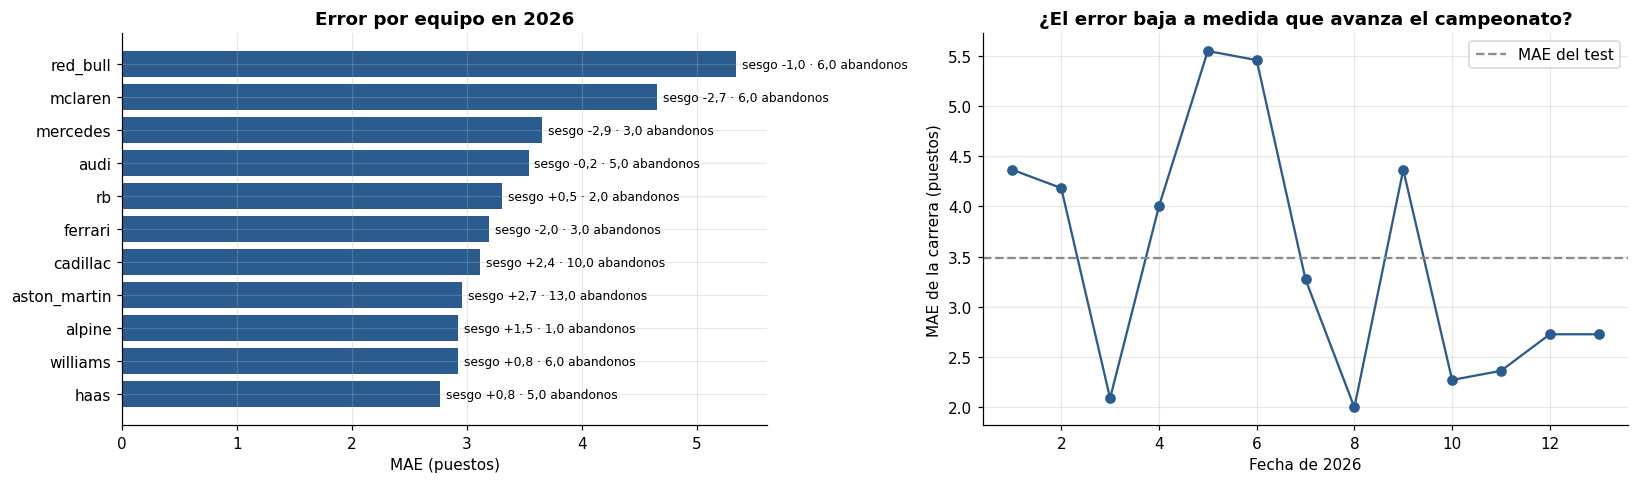

,Carrera,DriverId,TeamId,Q_GridPosition,Puesto,Puesto predicho,Error,Terminó
219,2026-R10,russell,mercedes,"3,0","22,0","2,0","-20,0",False
285,2026-R13,leclerc,ferrari,"3,0","22,0","3,0","-19,0",False
131,2026-R06,max_verstappen,red_bull,"2,0","22,0","4,0","-18,0",False
106,2026-R05,russell,mercedes,"1,0","19,0","2,0","-17,0",False
20,2026-R01,piastri,mclaren,"5,0","21,0","5,0","-16,0",False
19,2026-R01,hadjar,red_bull,"3,0","20,0","4,0","-16,0",False
263,2026-R12,max_verstappen,red_bull,"7,0","22,0","7,0","-15,0",False
41,2026-R02,norris,mclaren,"6,0","20,0","5,0","-15,0",False
105,2026-R05,norris,mclaren,"3,0","18,0","3,0","-15,0",False
109,2026-R05,arvid_lindblad,rb,"9,0","22,0","8,0","-14,0",False


In [ ]:
por_equipo = errores.groupby("TeamId").agg(n=("Error", "size"), MAE=("Error", lambda e: e.abs().mean()),
                                           sesgo=("Error", "mean"),
                                           abandonos=("Terminó", lambda t: int((t == False).sum())))
por_equipo = por_equipo.sort_values("MAE", ascending=False)
por_fecha = errores.groupby("RoundNumber")["Error"].agg(lambda e: e.abs().mean())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].barh(por_equipo.index, por_equipo["MAE"], color=AZUL)
for i, (eq, f) in enumerate(por_equipo.iterrows()):
    axes[0].text(f["MAE"] + 0.05, i, f"sesgo {f['sesgo']:+.1f} · {f['abandonos']} abandonos".replace(".", ","),
                 va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set_xlabel("MAE (puestos)")
axes[0].set_title(f"Error por equipo en {ANIO_TEST}")
axes[1].plot(por_fecha.index, por_fecha.values, marker="o", color=AZUL)
axes[1].axhline(err_abs.mean(), color=GRIS, linestyle="--", label="MAE del test")
axes[1].set_xlabel(f"Fecha de {ANIO_TEST}")
axes[1].set_ylabel("MAE de la carrera (puestos)")
axes[1].set_title("¿El error baja a medida que avanza el campeonato?")
axes[1].legend()
plt.tight_layout()
plt.show()

peores = errores.reindex(err_abs.sort_values(ascending=False).index).head(12)
mostrar(peores[["Carrera", "DriverId", "TeamId", "Q_GridPosition", "Puesto", "Puesto predicho", "Error", "Terminó"]],
        "Los 12 errores más grandes del test", decimales=1)

Los errores más grandes del test son pilotos de equipos de punta que largaron entre los primeros y
terminaron últimos. En casi todos la columna `Terminó` es falsa: no es que el modelo leyó mal su ritmo,
es que no terminaron la carrera.

### El ganador: donde la grilla acierta más que el modelo

En el test, la grilla sola acierta el ganador más veces que el modelo. Para cada GP se ve quién ganó,
quién tenía la pole y a quién puso primero el modelo, con la distancia al líder y Q_Best de los dos.

La lectura desde la F1: largar primero vale más de lo que un modelo lineal le puede dar. El
coeficiente de la grilla es el mismo para pasar del 15.º al 14.º que del 2.º al 1.º, pero en la punta
la pole significa aire limpio y la primera curva sin nadie adelante. Cuando el poleman tiene menos
puntos en el campeonato o peores vueltas de prácticas que el que larga 2.º o 3.º, el modelo pasa
adelante al otro, y ahí pierde el acierto que la grilla tiene gratis.

In [ ]:
datos_ganador = errores.join(te[["Q_Best_seconds_DBT_%", "DriverPoints_Before_DBT_%"]])
filas = []
for carrera, g in datos_ganador.groupby("Carrera"):
    real, pred, pole = (g.loc[g[c].idxmin()] for c in ["Puesto", "Puesto predicho", "Q_GridPosition"])
    filas.append({"Carrera": carrera, "Ganador": real["DriverId"], "Largó": real["Q_GridPosition"],
                  "Pole": pole["DriverId"], "Primero del modelo": pred["DriverId"],
                  "Ese largó": pred["Q_GridPosition"],
                  "Acierta la grilla": "sí" if pole["DriverId"] == real["DriverId"] else "no",
                  "Acierta el modelo": "sí" if pred["DriverId"] == real["DriverId"] else "no",
                  "Distancia al líder · pole": pole["DriverPoints_Before_DBT_%"],
                  "Distancia al líder · primero del modelo": pred["DriverPoints_Before_DBT_%"],
                  "Q_Best · pole": pole["Q_Best_seconds_DBT_%"],
                  "Q_Best · primero del modelo": pred["Q_Best_seconds_DBT_%"]})
tabla_ganador = pd.DataFrame(filas).set_index("Carrera")
mostrar(tabla_ganador, f"Test {ANIO_TEST}: el ganador según la grilla y según el modelo", decimales=2)

distinto = tabla_ganador["Primero del modelo"] != tabla_ganador["Pole"]
mostrar(pd.Series({
    "Carreras": len(tabla_ganador),
    "La grilla acierta el ganador": int((tabla_ganador["Acierta la grilla"] == "sí").sum()),
    "El modelo acierta el ganador": int((tabla_ganador["Acierta el modelo"] == "sí").sum()),
    "El modelo pone primero a alguien que no es el poleman": int(distinto.sum()),
    "  y gana el poleman": int((distinto & (tabla_ganador["Acierta la grilla"] == "sí")).sum()),
}, dtype=object).to_frame("Valor"), "Resumen del acierto del ganador en el test")

,Ganador,Largó,Pole,Primero del modelo,Ese largó,Acierta la grilla,Acierta el modelo,Distancia al líder · pole,Distancia al líder · primero del modelo,Q_Best · pole,Q_Best · primero del modelo
Carrera,,,,,,,,,,,
2026-R01,russell,"1,00",russell,russell,"1,00",sí,sí,—,—,"0,00","0,00"
2026-R02,antonelli,"1,00",antonelli,russell,"2,00",sí,no,"28,00","0,00","0,00","0,24"
2026-R03,antonelli,"1,00",antonelli,antonelli,"1,00",sí,sí,"7,84","7,84","0,00","0,00"
2026-R04,antonelli,"1,00",antonelli,antonelli,"1,00",sí,sí,"0,00","0,00","0,00","0,00"
2026-R05,antonelli,"2,00",russell,antonelli,"2,00",no,sí,"20,00","0,00","0,00","0,09"
2026-R06,antonelli,"1,00",antonelli,antonelli,"1,00",sí,sí,"0,00","0,00","0,00","0,00"
2026-R07,hamilton,"2,00",russell,russell,"1,00",no,no,"43,59","43,59","0,00","0,00"
2026-R08,russell,"1,00",russell,antonelli,"4,00",sí,no,"32,05","0,00","0,00","0,46"
2026-R09,leclerc,"2,00",antonelli,antonelli,"1,00",no,no,"0,00","0,00","0,00","0,00"


,Valor
Carreras,13
La grilla acierta el ganador,9
El modelo acierta el ganador,6
El modelo pone primero a alguien que no es el poleman,6
y gana el poleman,4


## Sección 9: El campeonato 2026 con los puntos predichos

El MAE en puestos mide cada carrera por separado. Otra forma de leer el modelo, más cercana a cómo se
usaría la aplicación, es preguntar cómo hubiera quedado el campeonato si cada carrera del test
terminaba en el orden predicho. En cada GP se ordenan los pilotos por la predicción, a cada uno se le
dan los puntos de ese puesto (25, 18, 15, 12, 10, 8, 6, 4, 2 y 1 del 1.º al 10.º) y se suman por
piloto. Lo mismo con la grilla (los puntos de su puesto de largada), con el dummy y con la realidad
(los puntos de su puesto de llegada). **Se hace solo con el modelo elegido.**

A tener en cuenta:

- **Los puntos reales se calculan con el puesto de llegada y la misma tabla**, sin sprints ni vuelta
  rápida. No son exactamente los del campeonato oficial, pero así todos se miden igual.
- **El dummy le da a todos el mismo puntaje**, así que en cada carrera empatan todos y se reparten
  los puntos en partes iguales.
- **Si hay empates en una predicción**, los empatados se reparten los puntos de los puestos que ocupan.
- **2026 está incompleta**: es el campeonato a la fecha, con las carreras que hay en el test.

| Métrica | Qué mira |
|---|---|
| **MAE de puntos por piloto** | Cuántos puntos de campeonato le erra en promedio a cada piloto. |
| **Error en el puesto del campeonato** | A cuántos puestos de su lugar real en el campeonato lo deja, en promedio. |
| **Spearman del campeonato** | Cuánto se parece el orden del campeonato predicho al real (1 = idéntico). |
| **Acierta el campeón** | Si el que más puntos suma es el campeón real a la fecha. |
| **Top 3 y top 10** | Cuántos de los 3 y de los 10 primeros reales quedan arriba en el predicho. |

,Modelo final (Lineal),Referencia: grilla sola,Piso: Dummy (media)
MAE de puntos por piloto,"14,78","10,26","56,76"
Error en el puesto del campeonato,"1,26","1,26","6,00"
Spearman del campeonato,"0,97","0,97",—
Acierta el campeón,sí,sí,—
Campeón predicho,antonelli,antonelli,—
"Del top 3 real, en su top 3",3,2,—
"Del top 10 real, en su top 10",10,9,—


,Puesto real,Puntos reales,Puesto · modelo,Puntos · modelo,Puesto · grilla,Puntos · grilla,Puntos · dummy,Modelo − real,Grilla − real,Carreras,Abandonos
Piloto,,,,,,,,,,,
antonelli,1,"241,0",1,"276,0",1,"234,0","59,7","35,0","-7,0",13,1
hamilton,2,"171,0",3,"184,0",4,"152,0","59,7","13,0","-19,0",13,0
russell,3,"167,0",2,"240,0",2,"225,0","59,7","73,0","58,0",13,2
norris,4,"139,0",5,"133,0",5,"139,0","59,7","-6,0","0,0",13,3
leclerc,5,"127,0",4,"167,0",3,"157,0","59,7","40,0","30,0",13,3
max_verstappen,6,"115,0",7,"96,0",6,"120,0","59,7","-19,0","5,0",13,4
piastri,7,"93,0",6,"102,0",7,"118,0","59,7","9,0","25,0",13,3
hadjar,8,"68,0",8,"39,0",8,"63,0","50,5","-29,0","-5,0",11,2
gasly,9,"48,0",9,"27,0",9,"42,0","59,7","-21,0","-6,0",13,1


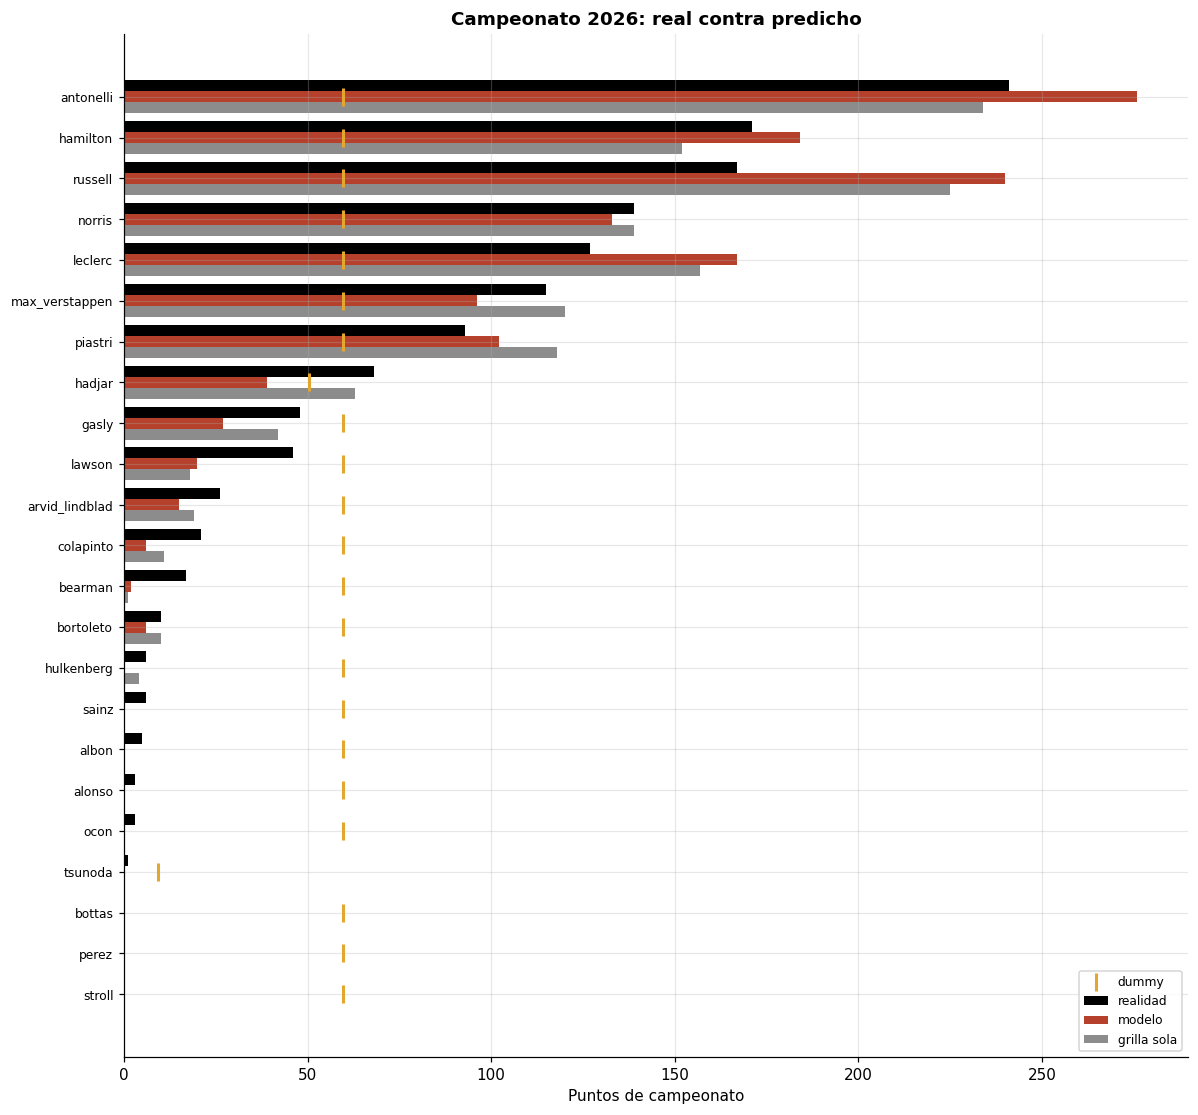

In [ ]:
PUNTOS = np.array([25, 18, 15, 12, 10, 8, 6, 4, 2, 1] + [0] * 30, dtype=float)
PUNTOS_ACUMULADOS = np.r_[0, np.cumsum(PUNTOS)]


def puntos_de_carrera(valores, carreras):
    # Puntos de cada piloto si la carrera termina en el orden de los valores (menor = mejor).
    # Los empatados se reparten los puntos de los puestos que ocupan.
    s = pd.Series(np.asarray(valores, dtype=float), index=carreras.index)
    desde = s.groupby(carreras).rank(method="min").astype(int).to_numpy()
    hasta = s.groupby(carreras).rank(method="max").astype(int).to_numpy()
    return pd.Series((PUNTOS_ACUMULADOS[hasta] - PUNTOS_ACUMULADOS[desde - 1]) / (hasta - desde + 1),
                     index=carreras.index)


def campeonato(valores):
    return puntos_de_carrera(valores, te["Carrera"]).groupby(te["DriverId"]).sum()


CAMPEONATOS = pd.DataFrame({"Realidad": campeonato(te["Puesto"]), PISO: campeonato(piso_te),
                            GRILLA: campeonato(grilla_te), FINAL: campeonato(pred_te)})
CAMPEONATOS.index.name = "Piloto"


def medir_campeonato(nombre):
    pred, real = CAMPEONATOS[nombre], CAMPEONATOS["Realidad"]
    top = lambda s, k: set(s.sort_values(ascending=False).head(k).index)
    elige = nombre != PISO
    return {"MAE de puntos por piloto": (pred - real).abs().mean(),
            "Error en el puesto del campeonato": (pred.rank(ascending=False) - real.rank(ascending=False)).abs().mean(),
            "Spearman del campeonato": pred.corr(real, method="spearman") if elige else np.nan,
            "Acierta el campeón": ("sí" if pred.idxmax() == real.idxmax() else "no") if elige else "—",
            "Campeón predicho": pred.idxmax() if elige else "—",
            "Del top 3 real, en su top 3": len(top(pred, 3) & top(real, 3)) if elige else np.nan,
            "Del top 10 real, en su top 10": len(top(pred, 10) & top(real, 10)) if elige else np.nan}


mostrar(pd.DataFrame({n: medir_campeonato(n) for n in [FINAL, GRILLA, PISO]}),
        f"Campeonato {ANIO_TEST} con los puntos predichos (campeón real a la fecha: {CAMPEONATOS['Realidad'].idxmax()})",
        decimales=2)

abandonos_piloto = te.assign(ab=(te["Terminó"] == False).astype(int)).groupby("DriverId")["ab"].sum()
t = pd.DataFrame({"Puntos reales": CAMPEONATOS["Realidad"], "Puntos · modelo": CAMPEONATOS[FINAL],
                  "Puntos · grilla": CAMPEONATOS[GRILLA], "Puntos · dummy": CAMPEONATOS[PISO]})
t.insert(0, "Puesto real", t["Puntos reales"].rank(ascending=False, method="min").astype(int))
t.insert(2, "Puesto · modelo", t["Puntos · modelo"].rank(ascending=False, method="min").astype(int))
t.insert(4, "Puesto · grilla", t["Puntos · grilla"].rank(ascending=False, method="min").astype(int))
t["Modelo − real"] = t["Puntos · modelo"] - t["Puntos reales"]
t["Grilla − real"] = t["Puntos · grilla"] - t["Puntos reales"]
t["Carreras"] = te.groupby("DriverId").size()
t["Abandonos"] = abandonos_piloto
t = t.sort_values(["Puesto real", "Puntos · grilla"], ascending=[True, False])
mostrar(t, f"Campeonato {ANIO_TEST}: puntos por piloto", decimales=1)

fig, ax = plt.subplots(figsize=(11, 0.38 * len(t) + 1.5))
y = np.arange(len(t))
ax.barh(y - 0.27, t["Puntos reales"], height=0.27, color="black", label="realidad")
ax.barh(y, t["Puntos · modelo"], height=0.27, color=ROJO, label="modelo")
ax.barh(y + 0.27, t["Puntos · grilla"], height=0.27, color=GRIS, label="grilla sola")
ax.plot(t["Puntos · dummy"], y, "|", color=AMARILLO, markersize=12, markeredgewidth=2, label="dummy")
ax.set_yticks(y, t.index, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Puntos de campeonato")
ax.set_title(f"Campeonato {ANIO_TEST}: real contra predicho")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

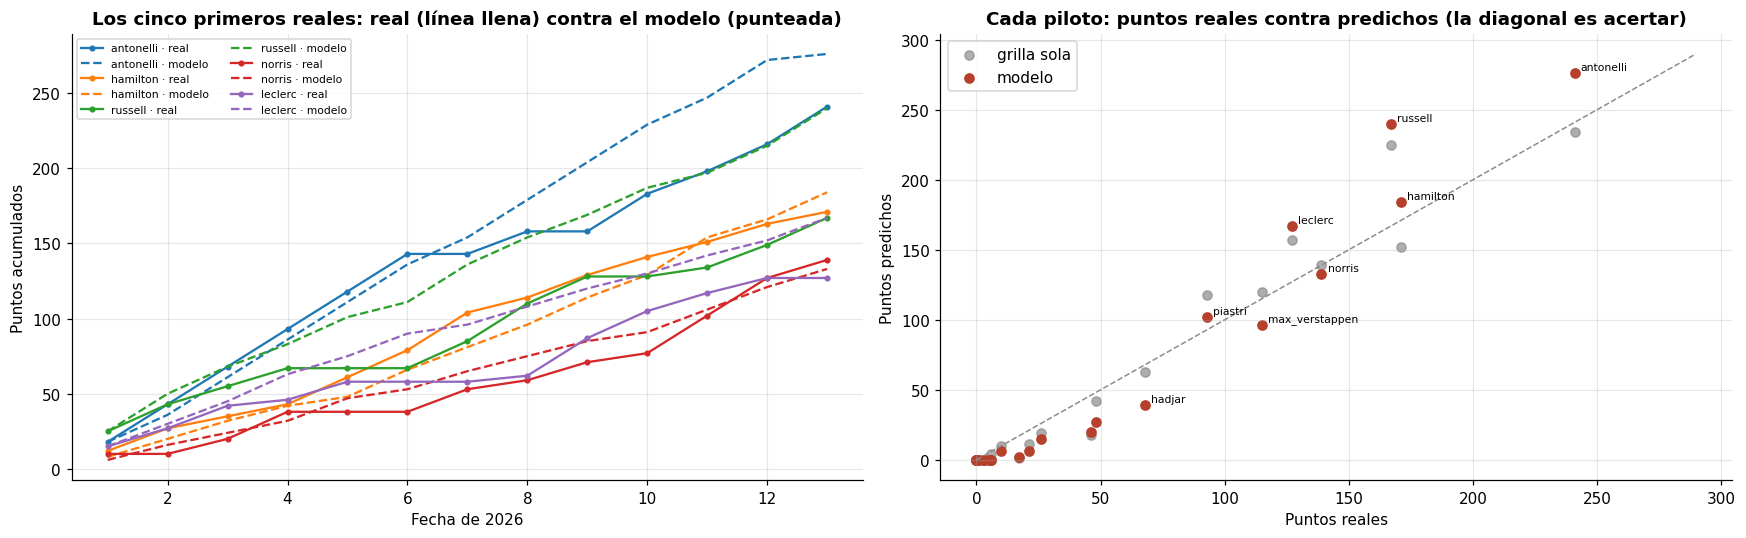

,Valor
Pilotos,23
El modelo queda más cerca que la grilla,4
La grilla queda más cerca,11
Empatan,8
Puntos errados en total · modelo,"340,00"
Puntos errados en total · grilla,"236,00"


,Puntos reales,Puntos · modelo,Puntos · grilla,Modelo − real,Carreras,Abandonos
Piloto,,,,,,
russell,"167,0","240,0","225,0","73,0",13,2
leclerc,"127,0","167,0","157,0","40,0",13,3
antonelli,"241,0","276,0","234,0","35,0",13,1
hadjar,"68,0","39,0","63,0","-29,0",11,2
lawson,"46,0","20,0","18,0","-26,0",13,1
gasly,"48,0","27,0","42,0","-21,0",13,1
max_verstappen,"115,0","96,0","120,0","-19,0",13,4
bearman,"17,0","2,0","1,0","-15,0",13,4


In [ ]:
pts_real = puntos_de_carrera(te["Puesto"], te["Carrera"])
pts_modelo = puntos_de_carrera(pred_te, te["Carrera"])
top5 = CAMPEONATOS["Realidad"].sort_values(ascending=False).head(5).index
real = CAMPEONATOS["Realidad"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colores = sns.color_palette("tab10")
for i, piloto in enumerate(top5):
    m = te["DriverId"] == piloto
    rondas = te.loc[m, "RoundNumber"]
    axes[0].plot(rondas, pts_real[m].cumsum(), color=colores[i], marker="o", markersize=3, label=f"{piloto} · real")
    axes[0].plot(rondas, pts_modelo[m].cumsum(), color=colores[i], linestyle="--", label=f"{piloto} · modelo")
axes[0].set_xlabel(f"Fecha de {ANIO_TEST}")
axes[0].set_ylabel("Puntos acumulados")
axes[0].set_title("Los cinco primeros reales: real (línea llena) contra el modelo (punteada)")
axes[0].legend(fontsize=7, ncol=2)

tope = max(real.max(), CAMPEONATOS[FINAL].max(), CAMPEONATOS[GRILLA].max()) * 1.05
axes[1].plot([0, tope], [0, tope], "--", color=GRIS, linewidth=1)
axes[1].scatter(real, CAMPEONATOS[GRILLA], color=GRIS, label="grilla sola", alpha=0.7)
axes[1].scatter(real, CAMPEONATOS[FINAL], color=ROJO, label="modelo")
for piloto in real.sort_values(ascending=False).head(8).index:
    axes[1].annotate(piloto, (real[piloto], CAMPEONATOS[FINAL][piloto]), fontsize=7,
                     xytext=(4, 2), textcoords="offset points")
axes[1].set_xlabel("Puntos reales")
axes[1].set_ylabel("Puntos predichos")
axes[1].set_title("Cada piloto: puntos reales contra predichos (la diagonal es acertar)")
axes[1].legend()
plt.tight_layout()
plt.show()

err_modelo = (CAMPEONATOS[FINAL] - real).abs()
err_grilla = (CAMPEONATOS[GRILLA] - real).abs()
mostrar(pd.Series({
    "Pilotos": len(real),
    "El modelo queda más cerca que la grilla": int((err_modelo < err_grilla).sum()),
    "La grilla queda más cerca": int((err_modelo > err_grilla).sum()),
    "Empatan": int((err_modelo == err_grilla).sum()),
    "Puntos errados en total · modelo": round(err_modelo.sum(), 1),
    "Puntos errados en total · grilla": round(err_grilla.sum(), 1),
}, dtype=object).to_frame("Valor"), "El modelo contra la grilla, piloto por piloto")

mostrar(t.reindex(t["Modelo − real"].abs().sort_values(ascending=False).index).head(8)
        [["Puntos reales", "Puntos · modelo", "Puntos · grilla", "Modelo − real", "Carreras", "Abandonos"]],
        "Los 8 pilotos en que el modelo más se equivoca en el campeonato", decimales=1)

En el campeonato el modelo y la grilla aciertan lo grueso: el mismo campeón a la fecha y casi el mismo
top 10, con un orden muy parecido al real. En los puntos por piloto la grilla queda algo más cerca.
Tiene sentido: los puntos se concentran en los primeros puestos, que es justo donde la grilla acierta
más (el ganador, por la pole) y donde los abandonos de los autos de punta cuestan más puntos. Los
pilotos en que más se equivoca el modelo son los que tuvieron abandonos: el modelo les da los puntos
de una carrera que no terminaron.

## Sección 10: En qué se apoya

### Importancia por permutación

Para cada columna se mezclan sus valores entre las filas del test y se mide cuánto empeora el MAE.
Se repite 30 veces. El desgaste se calcula con dos columnas en segundos, así que se permutan juntas
(la mejor vuelta y la promedio del mismo compuesto) para medir el desgaste como una sola columna.

,Suba del MAE · media,Suba · desvío
Columna,,
Q_GridPosition,"1,241","0,183"
DriverPoints_Before_DBT_%,"0,426","0,093"
Q_Best_seconds_DBT_%,"0,225","0,078"
FP_LapTime_min_SOFT_DBT_%,"0,116","0,054"
FP_LapTime_min_HARD_DBT_%,"0,029","0,020"
FP_LapTime_min_MED_DBT_%,"0,024","0,049"
FP_Desgaste_SOFT,"0,022","0,011"
FP_Desgaste_MED,"0,008","0,012"


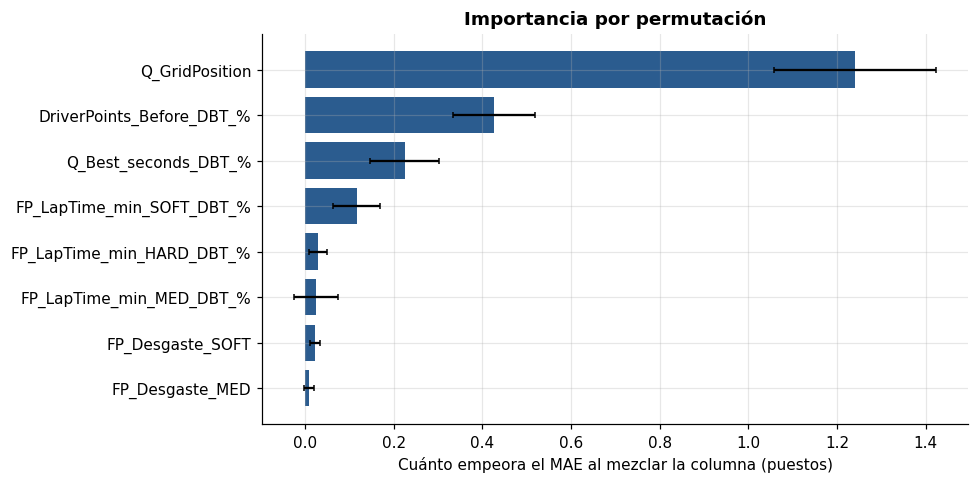

In [ ]:
GRUPOS_PERM = {c: [c] for c in COLUMNAS_BASE if c not in DESGASTE}
GRUPOS_PERM["FP_Desgaste_SOFT"] = ["FP_LapTime_min_SOFT_ABS", "FP_LapTime_mean_SOFT_ABS"]
GRUPOS_PERM["FP_Desgaste_MED"] = ["FP_LapTime_min_MED_ABS", "FP_LapTime_mean_MED_ABS"]

X_te_final = te[ENTRADA_FINAL]
mae_base = medir(final.predict(X_te_final), te)["MAE (puestos)"]
rng = np.random.default_rng(SEMILLA)
filas = []
for nombre, cols in GRUPOS_PERM.items():
    subas = []
    for _ in range(30):
        Xp = X_te_final.copy()
        orden = rng.permutation(len(Xp))
        Xp[cols] = X_te_final[cols].to_numpy()[orden]
        subas.append(medir(final.predict(Xp), te)["MAE (puestos)"] - mae_base)
    filas.append({"Columna": nombre, "Suba del MAE · media": np.mean(subas), "Suba · desvío": np.std(subas)})
importancia = pd.DataFrame(filas).set_index("Columna").sort_values("Suba del MAE · media", ascending=False)
mostrar(importancia, f"Importancia por permutación sobre el test (MAE base {mae_base:.3f})".replace(".", ","),
        decimales=3)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(importancia.index, importancia["Suba del MAE · media"], xerr=importancia["Suba · desvío"],
        color=AZUL, capsize=2)
ax.invert_yaxis()
ax.set_xlabel("Cuánto empeora el MAE al mezclar la columna (puestos)")
ax.set_title("Importancia por permutación")
plt.tight_layout()
plt.show()

### Coeficientes

Solo si el elegido es el lineal. Las columnas están escaladas, así que los coeficientes se comparan
entre sí. El objetivo va de 0 (ganador) a 1 (último): un **coeficiente positivo empuja hacia atrás**
y uno negativo, hacia adelante.

,Coeficiente,Signo
Columna (después del pipeline),,
Q_GridPosition,"0,0798",empuja hacia atrás
DriverPoints_Before_DBT_%,"0,0634",empuja hacia atrás
Q_Best_seconds_DBT_%,"0,0355",empuja hacia atrás
FP_LapTime_min_SOFT_DBT_%,"0,0157",empuja hacia atrás
FP_LapTime_min_MED_DBT_%,"0,0129",empuja hacia atrás
FP_LapTime_min_SOFT_DBT_% × FP_Desgaste_SOFT,"0,0071",empuja hacia atrás
FP_LapTime_min_MED_DBT_% × FP_Desgaste_MED,"0,0068",empuja hacia atrás
FP_LapTime_min_HARD_DBT_%,"0,0059",empuja hacia atrás
FP_Desgaste_SOFT,"-0,0058",empuja hacia adelante


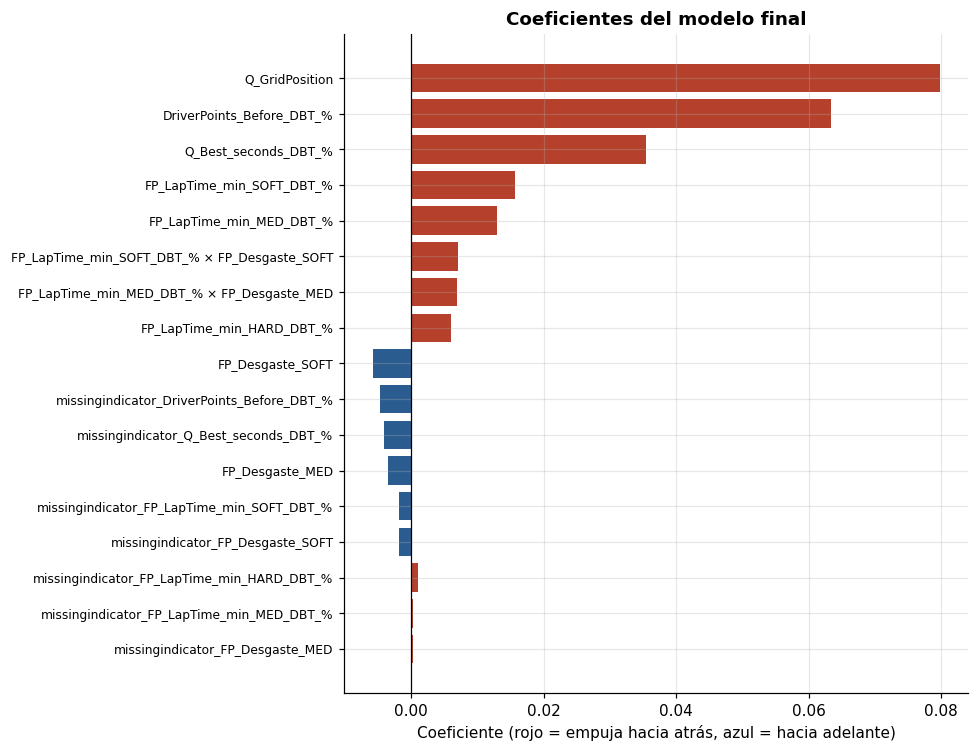

In [ ]:
if ELEGIDO == "Lineal":
    nombres = final[:-1].transform(te[ENTRADA_FINAL].head()).columns
    coefs = pd.DataFrame({"Coeficiente": final.named_steps["modelo"].coef_}, index=nombres)
    coefs["Signo"] = np.where(coefs["Coeficiente"] > 0, "empuja hacia atrás", "empuja hacia adelante")
    coefs = coefs.reindex(coefs["Coeficiente"].abs().sort_values(ascending=False).index)
    coefs.index.name = "Columna (después del pipeline)"
    mostrar(coefs, "Coeficientes del modelo final (columnas escaladas)", decimales=4)

    fig, ax = plt.subplots(figsize=(9, 0.32 * len(coefs) + 1.5))
    ax.barh(coefs.index, coefs["Coeficiente"], color=[ROJO if v > 0 else AZUL for v in coefs["Coeficiente"]])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.invert_yaxis()
    ax.tick_params(axis="y", labelsize=8)
    ax.set_xlabel("Coeficiente (rojo = empuja hacia atrás, azul = hacia adelante)")
    ax.set_title("Coeficientes del modelo final")
    plt.tight_layout()
    plt.show()
else:
    print(f"El modelo elegido ({ELEGIDO}) no es el lineal único; la lectura se hace con la permutación.")

Los signos son los esperables desde la F1: largar más atrás, estar más lejos del líder en el
campeonato y tener peores tiempos en la clasificación y en las prácticas empujan hacia atrás. La
grilla es la que más pesa, seguida por la distancia al líder y Q_Best; las mejores vueltas de
prácticas suman algo y el desgaste casi nada, que coincide con la Sección 6.

### Chequeo de fuga

La columna que más pesa es la grilla. Antes de festejar hay que descartar que alguna de las columnas
que más pesan traiga información del resultado:

- **`Q_GridPosition`:** se define en la clasificación, antes de la largada, con las penalizaciones
  ya aplicadas. No puede contener el resultado de la carrera.
- **`DriverPoints_Before_DBT_%`:** tiene que estar calculada con los puntos **anteriores** a la
  fecha. Si lo está, en la primera fecha de cada temporada tiene que faltar siempre (no hay puntos
  todavía) y los puntos acumulados de un piloto no pueden bajar de una fecha a la siguiente.
- **`Terminó`** (la única columna que sí se conoce después de la carrera) no está entre las entradas
  del modelo: se usa solo para medir.

Además, si hubiera fuga el número daría demasiado bien: un modelo que le gana a la grilla por
centésimas no es el síntoma de una columna que contiene la respuesta.

In [ ]:
seq = df.sort_values(["Year", "DriverId", "RoundNumber"])
saltos = seq.groupby(["Year", "DriverId"])["DriverPoints_Before"].diff().dropna()
chequeo_fuga = pd.Series({
    "Primera fecha: % de filas sin DriverPoints_Before_DBT_%":
        round(df.loc[df.RoundNumber == 1, "DriverPoints_Before_DBT_%"].isna().mean() * 100, 1),
    "Primera fecha: DriverPoints_Before máximo": df.loc[df.RoundNumber == 1, "DriverPoints_Before"].max(),
    "Fechas consecutivas en que los puntos acumulados bajan": int((saltos < 0).sum()),
    "Fechas consecutivas revisadas": len(saltos),
    "¿Alguna columna de resultado entre las entradas del modelo?":
        "no" if not set(ENTRADA_FINAL) & {"Terminó", "RACE_Position", "Puesto", "Puesto_01"} else "sí",
    "Spearman puntos al líder (antes) ~ resultado":
        round(df["DriverPoints_Before_DBT_%"].corr(df[target], method="spearman"), 3),
    "Spearman grilla ~ resultado": round(df["Q_GridPosition"].corr(df[target], method="spearman"), 3),
}, dtype=object).to_frame("Valor")
mostrar(chequeo_fuga, "Chequeo de fuga en las columnas que más pesan")

,Valor
Primera fecha: % de filas sin DriverPoints_Before_DBT_%,"100,00"
Primera fecha: DriverPoints_Before máximo,"0,00"
Fechas consecutivas en que los puntos acumulados bajan,0
Fechas consecutivas revisadas,3508
¿Alguna columna de resultado entre las entradas del modelo?,no
Spearman puntos al líder (antes) ~ resultado,"0,59"
Spearman grilla ~ resultado,"0,62"


La distancia al líder falta en todas las primeras fechas, los puntos acumulados nunca bajan y ninguna
columna de resultado entra al modelo. La correlación de la grilla y de la distancia al líder con el
resultado es alta pero lejos de 1, que es lo esperable de columnas previas a la carrera. No hay fuga.

## Sección 11: Conclusión y limitaciones

In [ ]:
resumen = pd.Series({
    "Modelo elegido": f"{ELEGIDO} ({legible(MEJORES_PARAMS)})",
    "MAE validación cruzada · piso": round(resultados_cv[PISO]["MAE (puestos)"].mean(), 3),
    "MAE validación cruzada · grilla": round(resultados_cv[GRILLA]["MAE (puestos)"].mean(), 3),
    "MAE validación cruzada · modelo": round(cv_elegido["MAE (puestos)"].mean(), 3),
    "MAE test · piso": round(tabla_test.loc[PISO, "MAE (puestos)"], 3),
    "MAE test · grilla": round(tabla_test.loc[GRILLA, "MAE (puestos)"], 3),
    "MAE test · modelo": round(tabla_test.loc[FINAL, "MAE (puestos)"], 3),
    "MAE test sin abandonos · grilla": round(tabla_test.loc[GRILLA, "MAE sin abandonos"], 3),
    "MAE test sin abandonos · modelo": round(tabla_test.loc[FINAL, "MAE sin abandonos"], 3),
    "AUC para anticipar abandonos (validación cruzada)":
        round(tabla_abandonos["AUC · todos"].mean(), 3) if "tabla_abandonos" in globals() else np.nan,
}, dtype=object).to_frame("Valor")
mostrar(resumen, "Resumen en números")

,Valor
Modelo elegido,Lineal (alpha=1000)
MAE validación cruzada · piso,"5,00"
MAE validación cruzada · grilla,"3,49"
MAE validación cruzada · modelo,"3,29"
MAE test · piso,"5,50"
MAE test · grilla,"3,50"
MAE test · modelo,"3,49"
MAE test sin abandonos · grilla,"1,96"
MAE test sin abandonos · modelo,"1,73"
AUC para anticipar abandonos (validación cruzada),"0,57"


- **Qué se predice y contra qué.** El orden de llegada de cada GP, a partir de un puntaje 0–1 por
  piloto, medido con MAE en puestos. El piso (dummy) erra unos 5 puestos y la grilla sola cerca de
  3,5. La grilla es la referencia que importa.
- **Cómo se validó.** Validación cruzada por temporada: cada temporada de 2020 a 2025 se valida
  entrenando con todas las demás. Partir al azar da la misma media pero un desvío tres veces menor, y
  deja ver útil a `TeamId` cuando no lo es. El esquema hacia adelante da casi el mismo error y la misma
  elección. El modelo final se entrena con 2018–2025 y se mide una sola vez sobre 2026.
- **El modelo.** Una regresión Ridge con las 8 columnas del EDA. Ajustados todos con su grilla,
  ningún otro modelo (árbol, bosque, boosting, zonas de grilla, ranking por carrera, promedio) le gana
  por más que el desvío, así que nos quedamos con el más simple, que además se lee por sus
  coeficientes.
- **Cuánto dice que la grilla no dijera.** En la validación cruzada le gana a la grilla en todas las
  temporadas. En el test, con todos los pilotos, quedan prácticamente empatados (3,49 contra 3,50).
  **Sin abandonos el modelo le gana con claridad** (1,73 contra 1,96 en el test), y el RMSE baja todavía
  más: el modelo ordena mejor que la grilla a los que terminan la carrera, y esa mejora queda tapada
  por los abandonos.
- **Dónde se equivoca.** En los abandonos: pocas filas que explican una parte grande del error. Los
  errores más grandes son autos de punta que largan adelante y no terminan. También acierta el
  ganador menos que la grilla, porque reparte el peso entre la pole y el ritmo.
- **En qué se apoya.** La grilla, la distancia al líder y Q_Best, con signos que tienen sentido. Las
  tres se conocen antes de la largada; no hay fuga.
- **El campeonato.** El modelo y la grilla aciertan el campeón a la fecha y casi todo el top 10; en
  los puntos por piloto la grilla queda algo más cerca, por la pole y por los abandonos de los autos
  de punta.

### Limitaciones

- **Los abandonos son la principal.** Con las columnas previas a la carrera no se pueden anticipar
  (AUC cerca de 0,5). Si tuviéramos información que ayude a predecirlos (fiabilidad de cada unidad de
  potencia, penalizaciones por cambio de componentes, probabilidad de safety car o de lluvia por
  circuito, historial de incidentes del piloto), el error con todos los pilotos se acercaría al sin
  abandonos y la ventaja del modelo sobre la grilla sería mucho más visible.
- **El ganador.** Un modelo lineal no le da a la pole el valor extra que tiene en la F1. Un término que
  distinga la primera fila del resto es una mejora posible para la Entrega 4.
- **La validación es algo optimista.** "Todas las demás temporadas" entrena con temporadas posteriores
  a la que valida. El esquema hacia adelante muestra que la diferencia es chica, y el test no depende
  de eso.
- **2026 está incompleta** y es la primera temporada de un reglamento nuevo con 22 autos. Que el error
  casi no suba es una buena señal de que las columnas relativas (DBT_%) y el puesto llevado a 0–1
  aguantan el cambio, pero son pocas carreras.

### Lo que probamos y no anduvo

El desgaste y los términos cruzados no aportan, pesar la distancia al líder por fecha empeora,
`TeamId` empeora fuera de su temporada, las columnas que el EDA descartó no mejoran, y los enfoques más
elaborados (zonas de grilla, ranking por carrera, promedio de modelos) no le ganan al lineal por más
que el desvío.

## Sección 12: Modelo para la aplicación

Se guarda el pipeline entrenado junto con la lista de columnas que necesita. La aplicación de la
Entrega 4 le pasa una fila por piloto de un GP con esas columnas, recibe el puntaje de cada uno y los
ordena para obtener los puestos. Las clases propias del notebook (`Desgaste`, `PesarDistanciaLider`,
`Interacciones` y, según el modelo elegido, `PorZonaDeGrilla` o `RankingPorCarrera`) tienen que estar
definidas en la aplicación para poder cargarlo.

In [ ]:
joblib.dump({"modelo": final, "entrada": ENTRADA_FINAL, "elegido": ELEGIDO,
             "hiperparametros": MEJORES_PARAMS, "semilla": SEMILLA},
            "modelo_f1_grupo14.joblib")
print("Guardado: modelo_f1_grupo14.joblib")
print("Columnas de entrada:", ", ".join(ENTRADA_FINAL))

Guardado: modelo_f1_grupo14.joblib
Columnas de entrada: Q_GridPosition, Q_Best_seconds_DBT_%, DriverPoints_Before_DBT_%, FP_LapTime_min_SOFT_DBT_%, FP_LapTime_min_MED_DBT_%, FP_LapTime_min_HARD_DBT_%, FP_LapTime_min_SOFT_ABS, FP_LapTime_mean_SOFT_ABS, FP_LapTime_min_MED_ABS, FP_LapTime_mean_MED_ABS, Carrera
